# **CitizenTech | Previsão da gravidade de sinistros de trânsito na cidade de São Paulo**

**Pergunta de ML:** quando um sinistro de trânsito com vítima acontece na capital paulista, dá para prever, só com o que se sabe no momento do registro (onde, quando, tipo de sinistro e veículos envolvidos), se ele terá **vítima fatal ou ferido grave**?

**Dados reais e públicos:** INFOSIGA SP (DETRAN-SP) e IBGE Censo 2022. Nenhum dado simulado é usado.

# **Setup e Instalação das Bibliotecas**

In [1]:
!pip install -q xgboost

import os
import zipfile
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, balanced_accuracy_score, accuracy_score,
                             confusion_matrix, roc_curve, precision_recall_curve)
from xgboost import XGBClassifier

SEED = 42
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#8a8984"
sns.set_theme(style="whitegrid", rc={"axes.edgecolor": "#cccccc", "grid.color": "#ececec"})
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

print("Ambiente configurado com sucesso.")

Ambiente configurado com sucesso.


# **Documentação das Fontes de Dados Reais (Fonte, Link e Período)**

In [2]:
POPULACAO_SP_CENSO_2022 = 11_451_999

fontes = pd.DataFrame([
    {"Fonte": "INFOSIGA SP - DETRAN-SP",
     "Conteúdo": "Todos os sinistros de trânsito registrados no estado de SP (data, hora, local, tipo, veículos e gravidade)",
     "Link": "https://infosiga.detran.sp.gov.br/",
     "Arquivo": "dados_infosiga.zip -> sinistros_2022-2024.csv e sinistros_2025-2026.csv",
     "Período usado": "jan/2022 até o último mês publicado",
     "Licença": "CC BY 4.0"},
    {"Fonte": "IBGE - Censo Demográfico 2022",
     "Conteúdo": "População residente do município de São Paulo (cód. 3550308)",
     "Link": "https://cidades.ibge.gov.br/brasil/sp/sao-paulo/panorama",
     "Arquivo": f"{POPULACAO_SP_CENSO_2022:,} habitantes".replace(",", "."),
     "Período usado": "2022",
     "Licença": "Dados públicos"},
])

print("--- Insight 1: Fontes oficiais utilizadas no projeto ---")
display(fontes)

--- Insight 1: Fontes oficiais utilizadas no projeto ---


,Fonte,Conteúdo,Link,Arquivo,Período usado,Licença
0,INFOSIGA SP - DETRAN-SP,Todos os sinistros de trânsito registrados no ...,https://infosiga.detran.sp.gov.br/,dados_infosiga.zip -> sinistros_2022-2024.csv ...,jan/2022 até o último mês publicado,CC BY 4.0
1,IBGE - Censo Demográfico 2022,População residente do município de São Paulo ...,https://cidades.ibge.gov.br/brasil/sp/sao-paul...,11.451.999 habitantes,2022,Dados públicos


# **Coleta dos Dados Reais do INFOSIGA SP (Download Oficial)**

In [3]:
URLS_INFOSIGA = [
    "https://infosiga.detran.sp.gov.br/rest/painel/download/file/dados_infosiga.zip",
    "https://github.com/viniciusoike/infosigasp/releases/download/data-current/dados_infosiga.zip",
]
ARQUIVO_ZIP = "dados_infosiga.zip"

if not (os.path.exists(ARQUIVO_ZIP) and zipfile.is_zipfile(ARQUIVO_ZIP)):
    for url in URLS_INFOSIGA:
        try:
            with requests.get(url, timeout=120, stream=True) as r:
                r.raise_for_status()
                with open(ARQUIVO_ZIP, "wb") as f:
                    for bloco in r.iter_content(chunk_size=1 << 20):
                        f.write(bloco)
            if zipfile.is_zipfile(ARQUIVO_ZIP):
                print("Download concluído:", url)
                break
        except Exception as erro:
            print(f"Não foi possível baixar de {url}: {type(erro).__name__}")

with zipfile.ZipFile(ARQUIVO_ZIP) as z:
    conteudo_zip = pd.DataFrame(
        [(i.filename, round(i.file_size / 1e6, 1), pd.Timestamp(*i.date_time).date()) for i in z.infolist()],
        columns=["arquivo", "tamanho_MB", "data_publicacao"])

print("--- Insight 2: Conteúdo do pacote oficial do INFOSIGA ---")
display(conteudo_zip)
print(f"Volume total publicado: {conteudo_zip.tamanho_MB.sum():,.0f} MB em {len(conteudo_zip)} arquivos.")

--- Insight 2: Conteúdo do pacote oficial do INFOSIGA ---


,arquivo,tamanho_MB,data_publicacao
0,pessoas_2015-2021.csv,164.0,2026-10-17
1,pessoas_2022-2024.csv,175.9,2026-10-17
2,pessoas_2025-2026.csv,81.1,2026-10-17
3,sinistros_2015-2021.csv,142.0,2026-10-17
4,sinistros_2022-2024.csv,157.9,2026-10-17
5,sinistros_2025-2026.csv,80.9,2026-10-17
6,veiculos_2015-2021.csv,59.5,2026-10-17
7,veiculos_2022-2024.csv,63.4,2026-10-17
8,veiculos_2025-2026.csv,28.6,2026-10-17


Volume total publicado: 953 MB em 9 arquivos.


# **Leitura dos Sinistros e Recorte da Cidade de São Paulo**

In [4]:
with zipfile.ZipFile(ARQUIVO_ZIP) as z:
    arquivos_sinistros = sorted(n for n in z.namelist()
                                if n.startswith("sinistros_") and int(n.split("_")[1][:4]) >= 2022)
    estado = pd.concat([pd.read_csv(z.open(n), sep=";", encoding="latin1", decimal=",", low_memory=False)
                        for n in arquivos_sinistros], ignore_index=True)

df = estado[estado["cod_ibge"].astype(str) == "3550308"].copy()

print("--- Insight 3: Peso da capital nos sinistros do estado ---")
print("Arquivos lidos:", arquivos_sinistros)
print(f"Sinistros no estado de SP: {len(estado):,}")
print(f"Sinistros na cidade de São Paulo: {len(df):,} ({len(df) / len(estado):.1%} do estado)")

--- Insight 3: Peso da capital nos sinistros do estado ---
Arquivos lidos: ['sinistros_2022-2024.csv', 'sinistros_2025-2026.csv']
Sinistros no estado de SP: 915,390
Sinistros na cidade de São Paulo: 212,311 (23.2% do estado)


# **Período Coberto pelos Dados**

In [5]:
df["data"] = pd.to_datetime(df["data_sinistro"], format="%d/%m/%Y", errors="coerce")

inicio, fim = df["data"].min(), df["data"].max()
meses = df["data"].dt.to_period("M").nunique()

print("--- Insight 4: Janela temporal dos dados reais ---")
print(f"Primeiro registro: {inicio:%d/%m/%Y} | Último registro: {fim:%d/%m/%Y}")
print(f"Meses cobertos: {meses} | Média de {len(df) / meses:,.0f} registros por mês na capital")

--- Insight 4: Janela temporal dos dados reais ---
Primeiro registro: 01/01/2022 | Último registro: 30/09/2026
Meses cobertos: 57 | Média de 3,725 registros por mês na capital


# **Tipos de Registro no INFOSIGA**

In [6]:
tipos = df["tipo_registro"].value_counts().to_frame("registros")
tipos["%"] = (tipos["registros"] / tipos["registros"].sum() * 100).round(1)

print("--- Insight 5: Composição dos registros ---")
display(tipos)
print("NOTIFICACAO são registros sem informação de vítimas (gravidade não preenchida) e ficam fora do modelo.")
print("O problema é tratado só nos sinistros com vítima: SINISTRO FATAL e SINISTRO NAO FATAL.")

--- Insight 5: Composição dos registros ---


,registros,%
tipo_registro,,
SINISTRO NAO FATAL,129635,61.1
NOTIFICACAO,78140,36.8
SINISTRO FATAL,4536,2.1


NOTIFICACAO são registros sem informação de vítimas (gravidade não preenchida) e ficam fora do modelo.
O problema é tratado só nos sinistros com vítima: SINISTRO FATAL e SINISTRO NAO FATAL.


# **Definição da Variável Alvo (Sinistro Grave ou Fatal)**

In [7]:
df = df[df["tipo_registro"].isin(["SINISTRO FATAL", "SINISTRO NAO FATAL"])].copy()

for c in ["qtd_gravidade_fatal", "qtd_gravidade_grave", "qtd_gravidade_leve", "qtd_gravidade_ileso"]:
    df[c] = df[c].fillna(0)

df["grave_ou_fatal"] = ((df["qtd_gravidade_fatal"] > 0) | (df["qtd_gravidade_grave"] > 0)).astype(int)

taxa = df["grave_ou_fatal"].mean()
print("--- Insight 6: Distribuição da variável alvo ---")
print(f"Sinistros com vítima analisados: {len(df):,}")
print(f"Com morte ou ferido grave: {df['grave_ou_fatal'].sum():,} ({taxa:.2%})")
print(f"Só com vítima fatal: {(df['qtd_gravidade_fatal'] > 0).sum():,} ({(df['qtd_gravidade_fatal'] > 0).mean():.2%})")
print(f"Classes desbalanceadas: cerca de 1 caso grave para cada {(1 - taxa) / taxa:.1f} casos leves.")

--- Insight 6: Distribuição da variável alvo ---
Sinistros com vítima analisados: 134,171
Com morte ou ferido grave: 13,879 (10.34%)
Só com vítima fatal: 4,536 (3.38%)
Classes desbalanceadas: cerca de 1 caso grave para cada 8.7 casos leves.


# **Diagnóstico de Qualidade (Valores Ausentes)**

In [8]:
colunas_checagem = ["hora_sinistro", "latitude", "longitude", "logradouro", "tipo_via", "tipo_local",
                    "tp_sinistro_primario", "qtd_pedestre", "qtd_motocicleta", "qtd_automovel"]
ausentes = (df[colunas_checagem].isna().mean() * 100).round(1).sort_values(ascending=False).to_frame("% ausente")
ausentes["% 'NAO DISPONIVEL'"] = [round((df[c].astype(str).str.upper() == "NAO DISPONIVEL").mean() * 100, 1)
                                  for c in ausentes.index]

print("--- Insight 7: Qualidade dos campos usados ---")
display(ausentes)
print("Nas colunas qtd_*, vazio significa zero veículos daquele tipo; nas demais é informação faltante.")

--- Insight 7: Qualidade dos campos usados ---


,% ausente,% 'NAO DISPONIVEL'
qtd_pedestre,87.6,0.0
qtd_automovel,39.4,0.0
qtd_motocicleta,35.9,0.0
latitude,5.1,0.0
longitude,5.1,0.0
tipo_local,1.2,22.8
logradouro,0.3,1.0
hora_sinistro,0.1,0.0
tipo_via,0.0,0.2
tp_sinistro_primario,0.0,1.7


Nas colunas qtd_*, vazio significa zero veículos daquele tipo; nas demais é informação faltante.


# **Limpeza e Padronização dos Dados**

In [9]:
antes = len(df)
df = df.drop_duplicates(subset="id_sinistro")
duplicados = antes - len(df)

df["hora"] = pd.to_datetime(df["hora_sinistro"], format="%H:%M", errors="coerce").dt.hour
df["mes"] = df["data"].dt.month
df["ano"] = df["data"].dt.year
df["dia_semana_num"] = df["data"].dt.dayofweek
df["fim_de_semana"] = (df["dia_semana_num"] >= 5).astype(int)

colunas_veiculos = ["qtd_pedestre", "qtd_bicicleta", "qtd_motocicleta", "qtd_automovel",
                    "qtd_onibus", "qtd_caminhao", "qtd_veic_outros"]
df[colunas_veiculos] = df[colunas_veiculos].fillna(0).astype(int)
df["total_veiculos"] = df[colunas_veiculos[1:]].sum(axis=1)

colunas_tipo = [c for c in df.columns if c.startswith("tp_sinistro_") and c != "tp_sinistro_primario"]
df[colunas_tipo] = (df[colunas_tipo] == "S").astype(int)

fora_da_cidade = ~(df["latitude"].between(-24.01, -23.35) & df["longitude"].between(-46.83, -46.36))
coords_invalidas = int((fora_da_cidade & df["latitude"].notna()).sum())
df.loc[fora_da_cidade, ["latitude", "longitude"]] = np.nan

for c in ["tipo_via", "tipo_local", "administracao", "circunscricao", "tp_sinistro_primario"]:
    df[c] = df[c].fillna("NAO DISPONIVEL").str.upper().str.strip()

print("--- Insight 8: Resultado da limpeza ---")
print(f"Duplicados removidos: {duplicados}")
print(f"Coordenadas fora do limite do município anuladas: {coords_invalidas}")
print(f"Registros sem hora válida: {df['hora'].isna().sum()}")
print(f"Base final limpa: {len(df):,} sinistros com vítima")

--- Insight 8: Resultado da limpeza ---
Duplicados removidos: 0
Coordenadas fora do limite do município anuladas: 394
Registros sem hora válida: 142
Base final limpa: 134,171 sinistros com vítima


# **Evolução Anual dos Sinistros e da Gravidade**

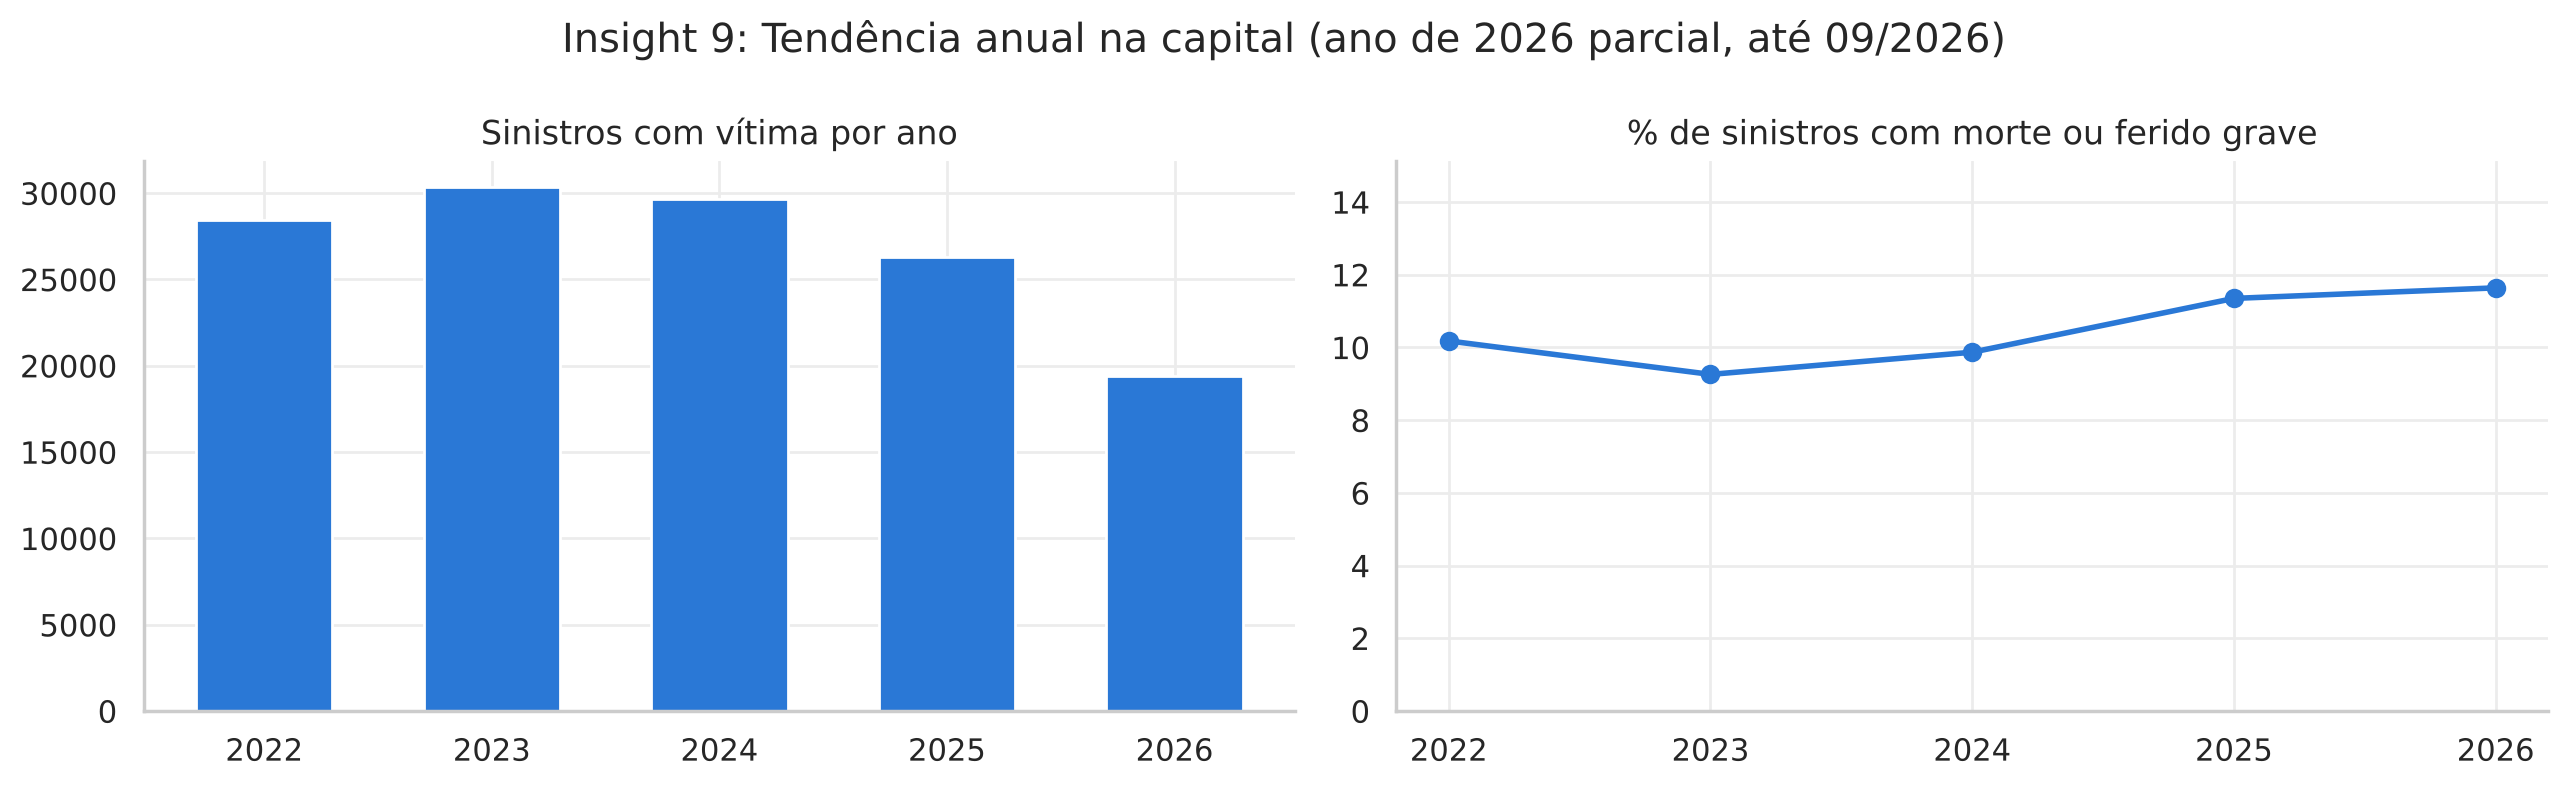

--- Insight 9: Tendência anual ---


,sinistros,graves_ou_fatais,taxa_grave_%
ano,,,
2022,28461,2898,10.18
2023,30350,2810,9.26
2024,29644,2925,9.87
2025,26323,2988,11.35
2026,19393,2258,11.64


In [10]:
anual = df.groupby("ano").agg(sinistros=("grave_ou_fatal", "size"),
                              graves_ou_fatais=("grave_ou_fatal", "sum"),
                              taxa_grave=("grave_ou_fatal", "mean"))
anual["taxa_grave_%"] = (anual["taxa_grave"] * 100).round(2)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(anual.index.astype(str), anual["sinistros"], color=AZUL, width=0.6)
ax[0].set_title("Sinistros com vítima por ano")
ax[1].plot(anual.index.astype(str), anual["taxa_grave_%"], color=AZUL, marker="o", lw=2)
ax[1].set_title("% de sinistros com morte ou ferido grave")
ax[1].set_ylim(0, anual["taxa_grave_%"].max() * 1.3)
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
plt.suptitle(f"Insight 9: Tendência anual na capital (ano de {fim.year} parcial, até {fim:%m/%Y})")
plt.tight_layout()
plt.show()

print("--- Insight 9: Tendência anual ---")
display(anual[["sinistros", "graves_ou_fatais", "taxa_grave_%"]])

# **Gravidade por Hora do Dia**

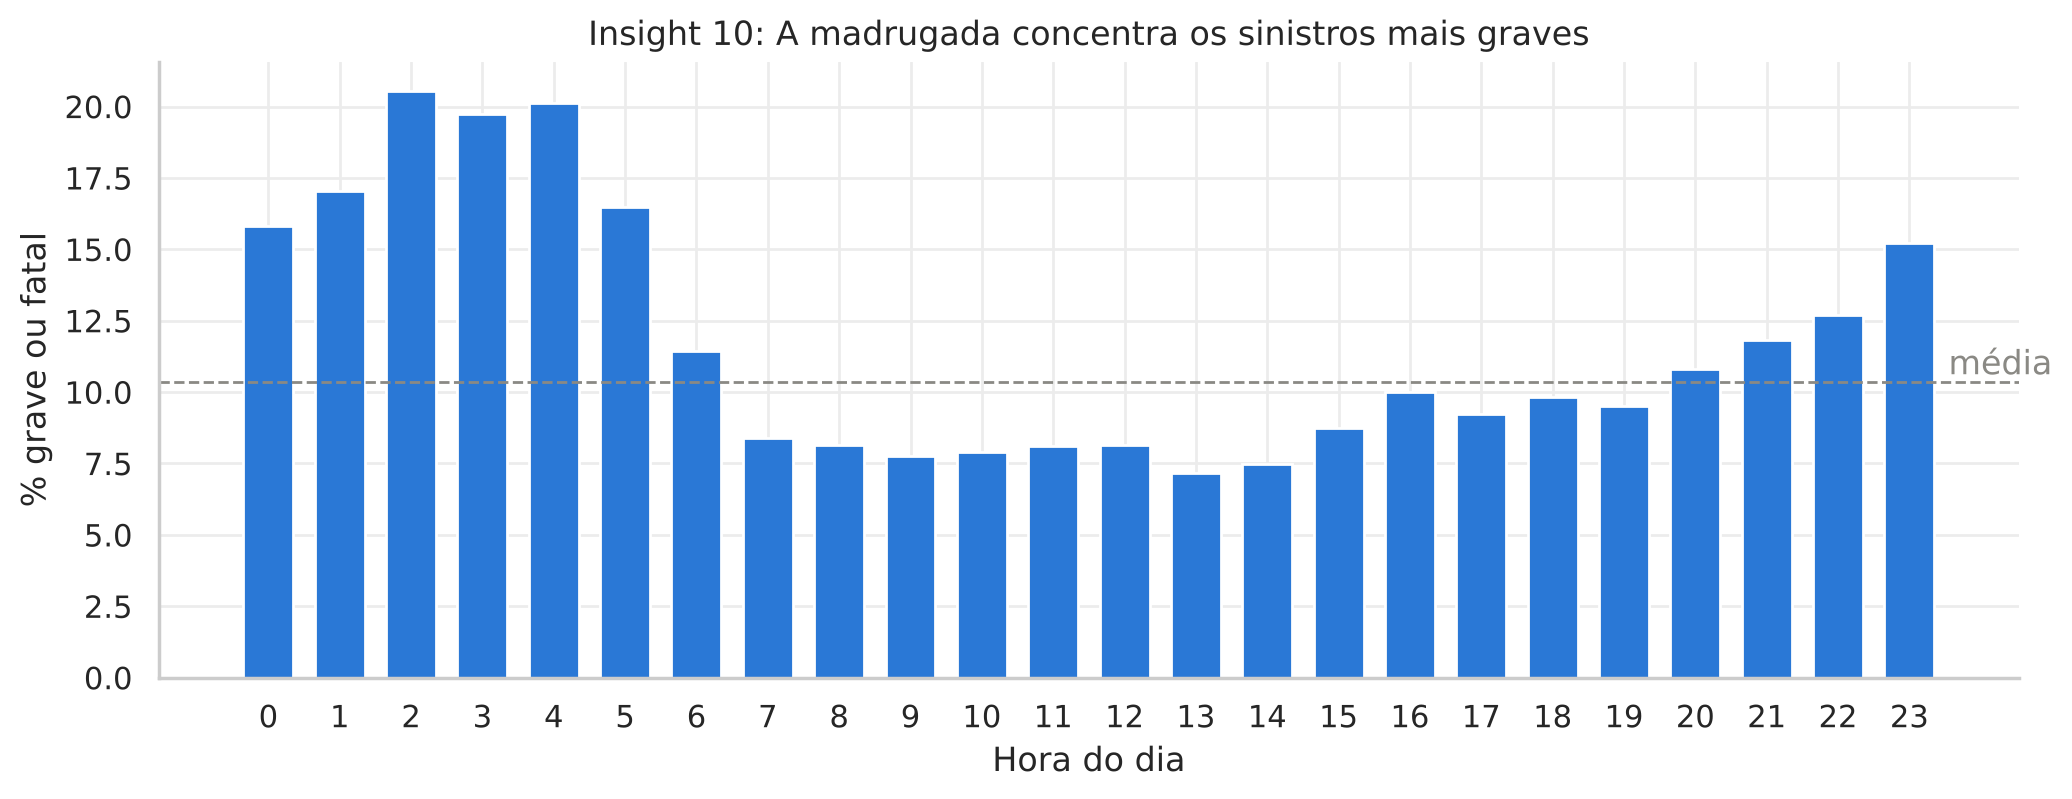

--- Insight 10: Gravidade ao longo do dia ---
Hora mais crítica: 2h (20.5% graves) | Hora menos crítica: 13h (7.2%)
Hora com mais sinistros: 18h (8,410 registros)


In [11]:
por_hora = df.dropna(subset=["hora"]).groupby("hora")["grave_ou_fatal"].agg(["size", "mean"])

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(por_hora.index, por_hora["mean"] * 100, color=AZUL, width=0.7)
ax.axhline(taxa * 100, color=CINZA, ls="--", lw=1)
ax.text(23.4, taxa * 100, " média", va="bottom", color=CINZA)
ax.set_xticks(range(24))
ax.set_xlabel("Hora do dia")
ax.set_ylabel("% grave ou fatal")
ax.spines[["top", "right"]].set_visible(False)
plt.title("Insight 10: A madrugada concentra os sinistros mais graves")
plt.show()

pico, vale = por_hora["mean"].idxmax(), por_hora["mean"].idxmin()
print("--- Insight 10: Gravidade ao longo do dia ---")
print(f"Hora mais crítica: {int(pico)}h ({por_hora['mean'].max():.1%} graves) | "
      f"Hora menos crítica: {int(vale)}h ({por_hora['mean'].min():.1%})")
print(f"Hora com mais sinistros: {int(por_hora['size'].idxmax())}h ({por_hora['size'].max():,} registros)")

# **Gravidade por Dia da Semana**

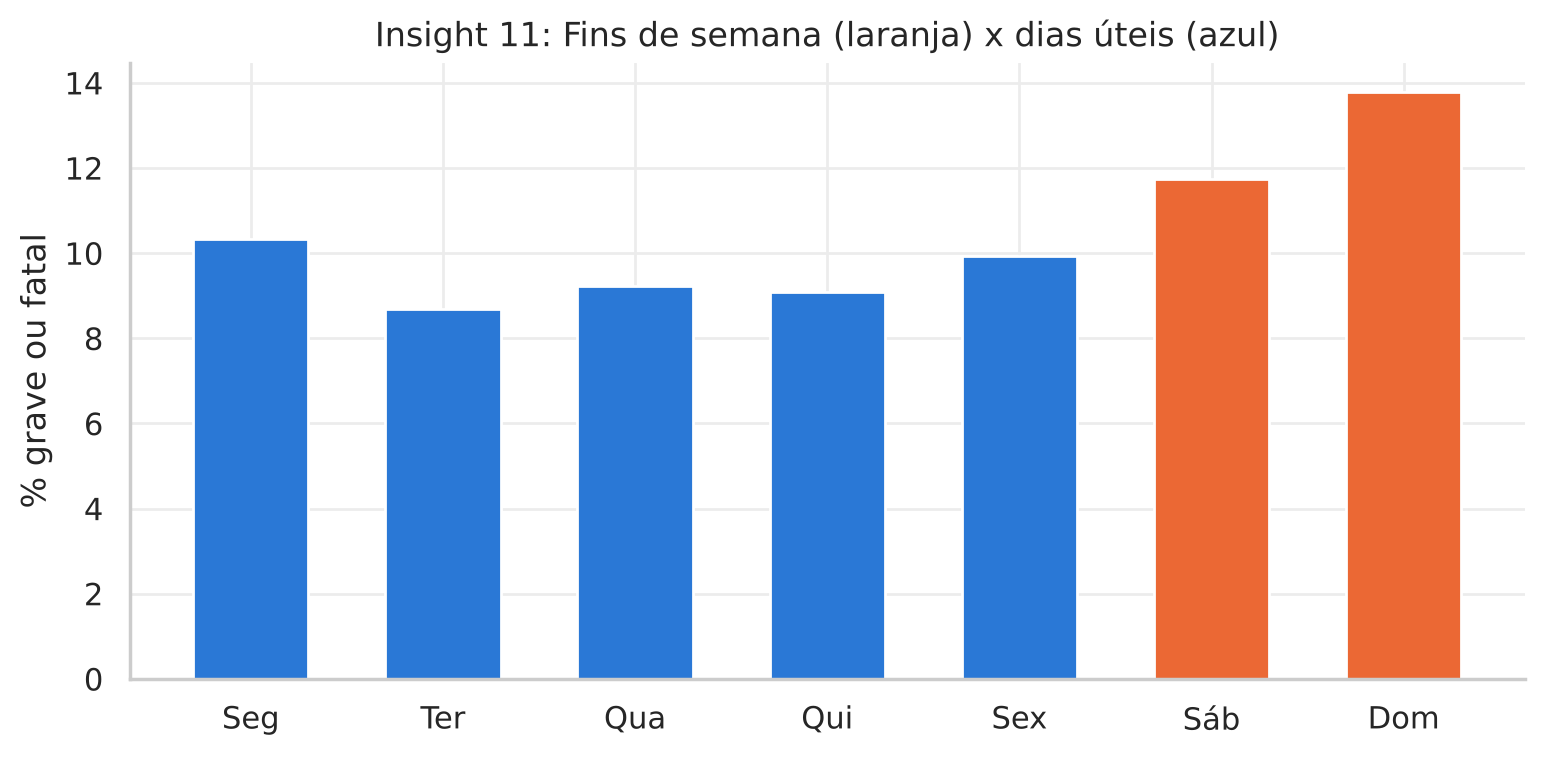

--- Insight 11: Efeito do fim de semana ---
Dias úteis: 9.46% graves | Fins de semana: 12.69% graves (+34% de risco relativo)


In [12]:
nomes_dias = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]
por_dia = df.groupby("dia_semana_num")["grave_ou_fatal"].agg(["size", "mean"])
por_dia.index = nomes_dias

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(por_dia.index, por_dia["mean"] * 100, color=[AZUL] * 5 + [LARANJA] * 2, width=0.6)
ax.set_ylabel("% grave ou fatal")
ax.spines[["top", "right"]].set_visible(False)
plt.title("Insight 11: Fins de semana (laranja) x dias úteis (azul)")
plt.show()

fds = df.groupby("fim_de_semana")["grave_ou_fatal"].mean()
print("--- Insight 11: Efeito do fim de semana ---")
print(f"Dias úteis: {fds[0]:.2%} graves | Fins de semana: {fds[1]:.2%} graves "
      f"({fds[1] / fds[0] - 1:+.0%} de risco relativo)")

# **Gravidade por Tipo de Sinistro**

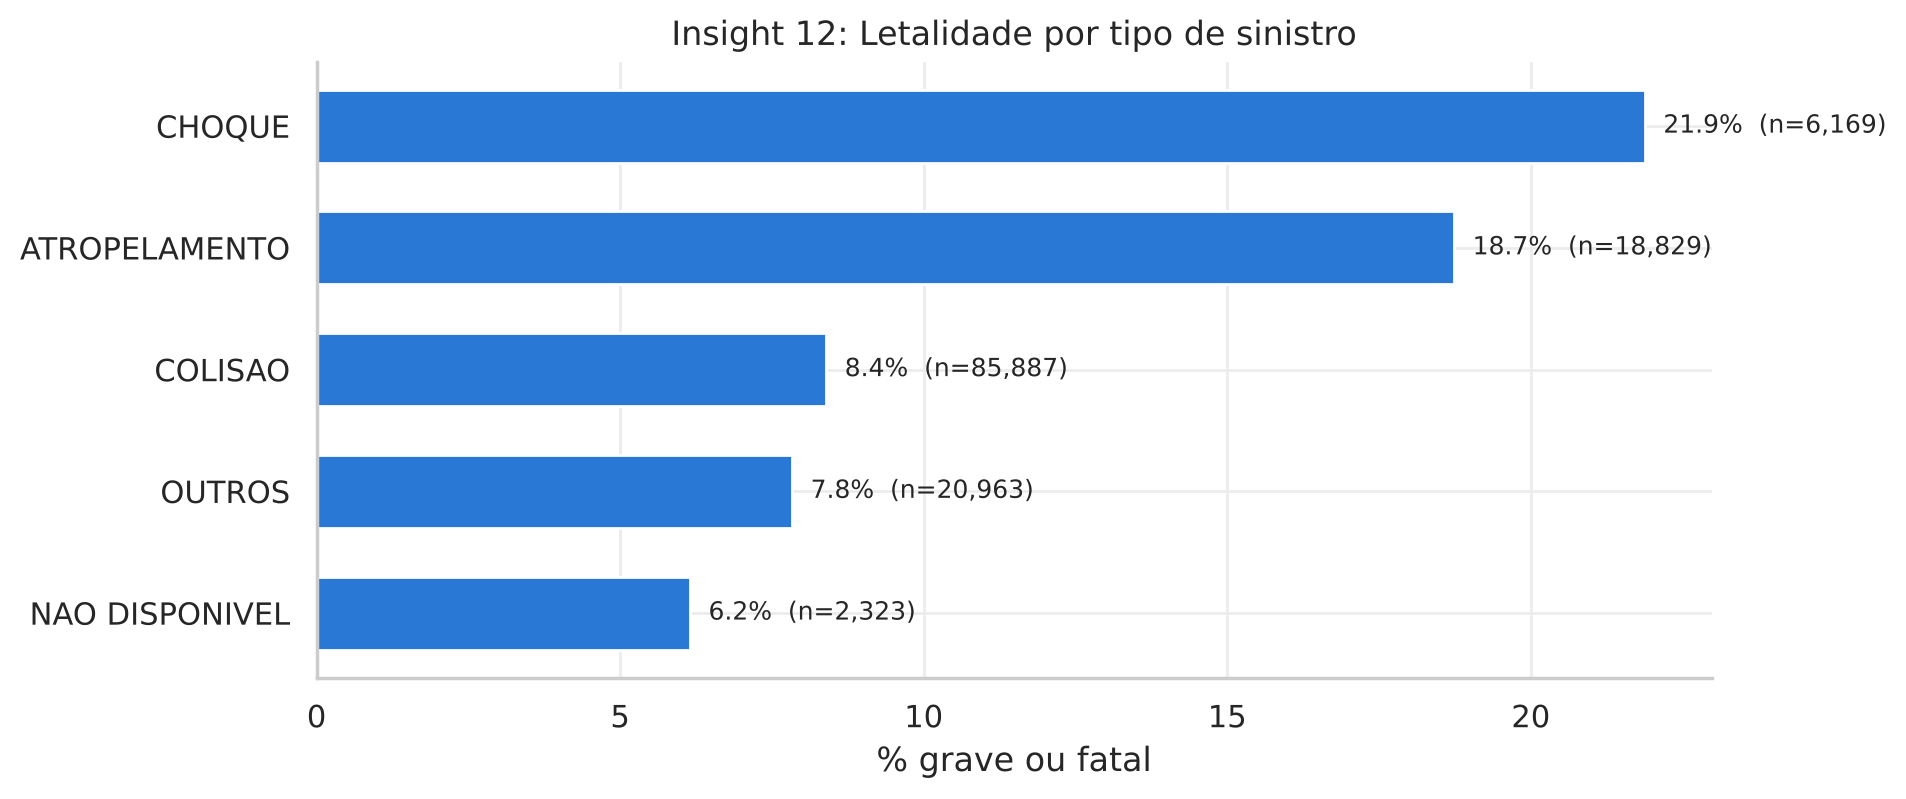

--- Insight 12: Atropelamento x colisão ---
Atropelamentos são graves em 18.7% dos casos, 2.2x a taxa das colisões (8.4%).


In [13]:
por_tipo = (df.groupby("tp_sinistro_primario")["grave_ou_fatal"].agg(["size", "mean"])
              .sort_values("mean"))

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(por_tipo.index, por_tipo["mean"] * 100, color=AZUL, height=0.6)
for i, (n, m) in enumerate(zip(por_tipo["size"], por_tipo["mean"])):
    ax.text(m * 100 + 0.3, i, f"{m:.1%}  (n={n:,})", va="center", fontsize=9)
ax.set_xlabel("% grave ou fatal")
ax.spines[["top", "right"]].set_visible(False)
plt.title("Insight 12: Letalidade por tipo de sinistro")
plt.show()

atrop = por_tipo.loc["ATROPELAMENTO", "mean"]
colis = por_tipo.loc["COLISAO", "mean"]
print("--- Insight 12: Atropelamento x colisão ---")
print(f"Atropelamentos são graves em {atrop:.1%} dos casos, {atrop / colis:.1f}x a taxa das colisões ({colis:.1%}).")

# **Usuários Vulneráveis: Pedestres, Motociclistas e Ciclistas**

In [14]:
grupos = {"Pedestre envolvido": df["qtd_pedestre"] > 0,
          "Moto envolvida": df["qtd_motocicleta"] > 0,
          "Bicicleta envolvida": df["qtd_bicicleta"] > 0,
          "Ônibus envolvido": df["qtd_onibus"] > 0,
          "Caminhão envolvido": df["qtd_caminhao"] > 0,
          "Só automóveis": (df["qtd_automovel"] > 0) & (df["total_veiculos"] == df["qtd_automovel"]) & (df["qtd_pedestre"] == 0)}

vulneraveis = pd.DataFrame({k: {"participação_%": m.mean() * 100,
                                "taxa_grave_%": df.loc[m, "grave_ou_fatal"].mean() * 100}
                            for k, m in grupos.items()}).T.round(1).sort_values("taxa_grave_%", ascending=False)

print("--- Insight 13: Quem está envolvido muda a gravidade ---")
display(vulneraveis)
print(f"Motos aparecem em {vulneraveis.loc['Moto envolvida', 'participação_%']:.0f}% dos sinistros com vítima da capital.")

--- Insight 13: Quem está envolvido muda a gravidade ---


,participação_%,taxa_grave_%
Pedestre envolvido,12.4,19.9
Caminhão envolvido,3.3,17.9
Bicicleta envolvida,2.2,12.3
Ônibus envolvido,7.3,11.3
Moto envolvida,64.1,10.8
Só automóveis,14.3,7.2


Motos aparecem em 64% dos sinistros com vítima da capital.


# **Vias Urbanas x Rodovias**

In [15]:
por_via = (df[df["tipo_via"] != "NAO DISPONIVEL"].groupby("tipo_via")["grave_ou_fatal"]
             .agg(sinistros="size", taxa_grave="mean"))
por_via["taxa_grave"] = (por_via["taxa_grave"] * 100).round(2)

print("--- Insight 14: Gravidade por tipo de via ---")
display(por_via.sort_values("sinistros", ascending=False))
risco_rodovia = por_via.loc["ESTRADAS E RODOVIAS", "taxa_grave"] / por_via.loc["VIAS URBANAS", "taxa_grave"]
print(f"Rodovias e estradas dentro do município têm {risco_rodovia:.2f}x a taxa de gravidade das vias urbanas.")
print("Registros com tipo_via 'NAO DISPONIVEL' são analisados na auditoria de vazamento mais adiante.")

--- Insight 14: Gravidade por tipo de via ---


,sinistros,taxa_grave
tipo_via,,
VIAS URBANAS,124247,9.91
ESTRADAS E RODOVIAS,9610,13.01


Rodovias e estradas dentro do município têm 1.31x a taxa de gravidade das vias urbanas.
Registros com tipo_via 'NAO DISPONIVEL' são analisados na auditoria de vazamento mais adiante.


# **Mapa de Calor Geográfico dos Sinistros Graves**

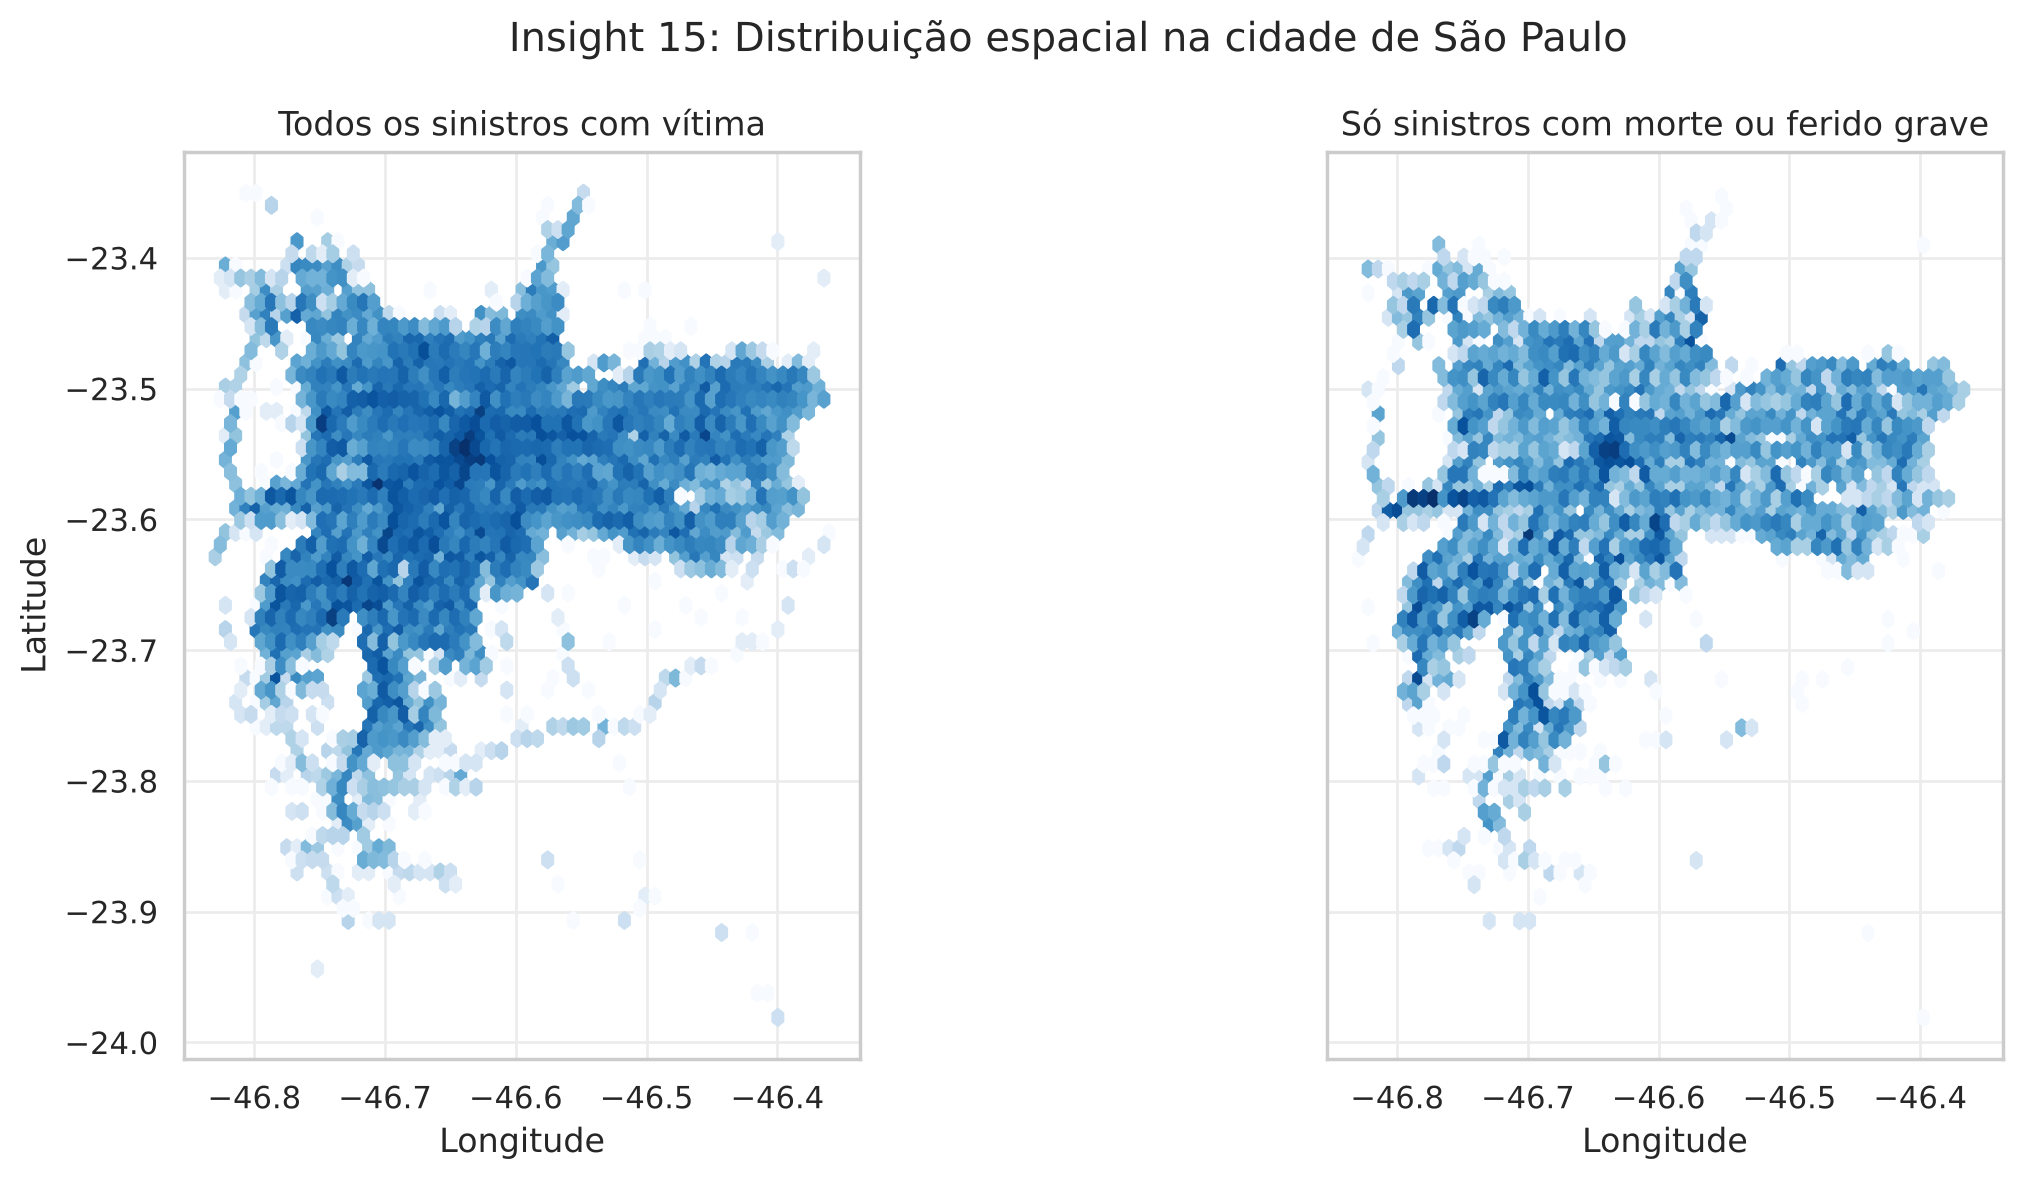

--- Insight 15: Cobertura geográfica ---
Sinistros com coordenada válida: 126,956 (94.6% da base)


In [16]:
geo = df.dropna(subset=["latitude", "longitude"])

fig, ax = plt.subplots(1, 2, figsize=(13, 6), sharex=True, sharey=True)
ax[0].hexbin(geo["longitude"], geo["latitude"], gridsize=60, cmap="Blues", mincnt=1, bins="log")
ax[0].set_title("Todos os sinistros com vítima")
ax[1].hexbin(geo.loc[geo.grave_ou_fatal == 1, "longitude"], geo.loc[geo.grave_ou_fatal == 1, "latitude"],
             gridsize=60, cmap="Blues", mincnt=1, bins="log")
ax[1].set_title("Só sinistros com morte ou ferido grave")
for a in ax:
    a.set_xlabel("Longitude")
    a.set_aspect("equal")
ax[0].set_ylabel("Latitude")
plt.suptitle("Insight 15: Distribuição espacial na cidade de São Paulo")
plt.tight_layout()
plt.show()

print("--- Insight 15: Cobertura geográfica ---")
print(f"Sinistros com coordenada válida: {len(geo):,} ({len(geo) / len(df):.1%} da base)")

# **Vias com Mais Sinistros Graves ou Fatais**

In [17]:
top_vias = (df[df.grave_ou_fatal == 1].groupby("logradouro").size().sort_values(ascending=False).head(10)
              .to_frame("graves_ou_fatais"))
top_vias["mortes"] = df[df.logradouro.isin(top_vias.index)].groupby("logradouro")["qtd_gravidade_fatal"].sum()

print("--- Insight 16: Top 10 vias mais perigosas da capital no período ---")
display(top_vias.astype(int))
print(f"Essas 10 vias somam {top_vias.graves_ou_fatais.sum() / df.grave_ou_fatal.sum():.1%} de todos os casos graves da cidade.")

--- Insight 16: Top 10 vias mais perigosas da capital no período ---


,graves_ou_fatais,mortes
logradouro,,
SP 270,314,54
SP 021,191,41
SP 015 - PINHEIROS,176,85
SP 015 - TIETE,165,100
BR 381,145,89
ESTRADA DE ITAPECERICA,138,29
SP 330,129,65
SP 348,125,63
AVENIDA SAPOPEMBA,104,32


Essas 10 vias somam 11.5% de todos os casos graves da cidade.


# **Mortes no Trânsito por 100 mil Habitantes (INFOSIGA + IBGE)**

In [18]:
mortes_ano = df.groupby("ano")["qtd_gravidade_fatal"].sum().to_frame("mortes")
mortes_ano["por_100_mil_hab"] = (mortes_ano["mortes"] / POPULACAO_SP_CENSO_2022 * 1e5).round(2)

print("--- Insight 17: Taxa de mortalidade no trânsito da capital ---")
display(mortes_ano.astype({"mortes": int}))
print(f"Referência populacional: IBGE Censo 2022 ({POPULACAO_SP_CENSO_2022:,} hab.). "
      f"{fim.year} contém apenas dados até {fim:%m/%Y}.".replace(",", "."))

--- Insight 17: Taxa de mortalidade no trânsito da capital ---


,mortes,por_100_mil_hab
ano,,
2022,866,7.56
2023,933,8.15
2024,1051,9.18
2025,1038,9.06
2026,777,6.78


Referência populacional: IBGE Censo 2022 (11.451.999 hab.). 2026 contém apenas dados até 09/2026.


# **Auditoria de Vazamento de Dados (Data Leakage)**

In [19]:
fatal = df["tipo_registro"] == "SINISTRO FATAL"
checagens = {
    "tipo_via = NAO DISPONIVEL": df["tipo_via"] == "NAO DISPONIVEL",
    "circunscricao = NAO DISPONIVEL": df["circunscricao"] == "NAO DISPONIVEL",
    "tp_sinistro_colisao_outros = S": df["tp_sinistro_colisao_outros"] == 1,
    "tp_sinistro_outros = S": df["tp_sinistro_outros"] == 1,
    "tipo_local = NAO DISPONIVEL": df["tipo_local"] == "NAO DISPONIVEL",
    "tp_sinistro_primario = NAO DISPONIVEL": df["tp_sinistro_primario"] == "NAO DISPONIVEL",
    "sem coordenada válida": df["latitude"].isna(),
}
auditoria = pd.DataFrame({k: {"% nos registros fatais": m[fatal].mean() * 100,
                              "% nos registros não fatais": m[~fatal].mean() * 100}
                          for k, m in checagens.items()}).T.round(1)

print("--- Insight 18: Campos preenchidos de forma diferente nos registros fatais ---")
display(auditoria)
print("Os registros fatais passam por outra rotina de coleta (investigação do óbito) e usam outro padrão de preenchimento.")
print("Se esses campos entrassem no modelo, ele aprenderia a reconhecer o 'formulário' do caso fatal, e não o risco real.")
print("Decisão: remover as flags secundárias tp_sinistro_*, tipo_local, administracao e circunscricao;")
print("tipo_via vira o indicador 'rodovia'; tipo primário 'NAO DISPONIVEL' vira 'OUTROS'; sinistros sem coordenada saem do modelo.")

--- Insight 18: Campos preenchidos de forma diferente nos registros fatais ---


,% nos registros fatais,% nos registros não fatais
tipo_via = NAO DISPONIVEL,6.8,0.0
circunscricao = NAO DISPONIVEL,6.8,0.5
tp_sinistro_colisao_outros = S,8.6,0.0
tp_sinistro_outros = S,8.4,47.3
tipo_local = NAO DISPONIVEL,4.9,24.6
tp_sinistro_primario = NAO DISPONIVEL,0.0,1.8
sem coordenada válida,10.3,5.2


Os registros fatais passam por outra rotina de coleta (investigação do óbito) e usam outro padrão de preenchimento.
Se esses campos entrassem no modelo, ele aprenderia a reconhecer o 'formulário' do caso fatal, e não o risco real.
Decisão: remover as flags secundárias tp_sinistro_*, tipo_local, administracao e circunscricao;
tipo_via vira o indicador 'rodovia'; tipo primário 'NAO DISPONIVEL' vira 'OUTROS'; sinistros sem coordenada saem do modelo.


# **Engenharia de Atributos e Codificação**

In [20]:
base_modelo = df.dropna(subset=["latitude", "longitude"]).copy()
base_modelo["rodovia"] = (base_modelo["tipo_via"] == "ESTRADAS E RODOVIAS").astype(int)
base_modelo["madrugada"] = base_modelo["hora"].between(0, 5).astype(int)
base_modelo["tem_vulneravel"] = ((base_modelo["qtd_pedestre"] + base_modelo["qtd_motocicleta"]
                                  + base_modelo["qtd_bicicleta"]) > 0).astype(int)
base_modelo["tipo_primario"] = base_modelo["tp_sinistro_primario"].replace("NAO DISPONIVEL", "OUTROS")

atributos_numericos = (["hora", "mes", "dia_semana_num", "fim_de_semana", "madrugada", "latitude", "longitude",
                        "rodovia", "tem_vulneravel", "total_veiculos"] + colunas_veiculos)

X_total = pd.concat([base_modelo[atributos_numericos],
                     pd.get_dummies(base_modelo["tipo_primario"], prefix="tipo", dtype=int)], axis=1)
y_total = base_modelo["grave_ou_fatal"]

print("--- Insight 19: Atributos que o modelo recebe ---")
print(f"Registros no modelo: {len(X_total):,} ({len(X_total) / len(df):.1%} da base limpa)")
print(f"Taxa de graves mantida: {y_total.mean():.2%} (antes: {df['grave_ou_fatal'].mean():.2%})")
print(f"Atributos: {X_total.shape[1]} -> {list(X_total.columns)}")
print("Ficaram de fora: qtd_gravidade_*, tipo_registro e os campos com padrão de preenchimento diferente.")

--- Insight 19: Atributos que o modelo recebe ---
Registros no modelo: 126,956 (94.6% da base limpa)
Taxa de graves mantida: 10.23% (antes: 10.34%)
Atributos: 21 -> ['hora', 'mes', 'dia_semana_num', 'fim_de_semana', 'madrugada', 'latitude', 'longitude', 'rodovia', 'tem_vulneravel', 'total_veiculos', 'qtd_pedestre', 'qtd_bicicleta', 'qtd_motocicleta', 'qtd_automovel', 'qtd_onibus', 'qtd_caminhao', 'qtd_veic_outros', 'tipo_ATROPELAMENTO', 'tipo_CHOQUE', 'tipo_COLISAO', 'tipo_OUTROS']
Ficaram de fora: qtd_gravidade_*, tipo_registro e os campos com padrão de preenchimento diferente.


# **Correlação dos Atributos com a Gravidade**

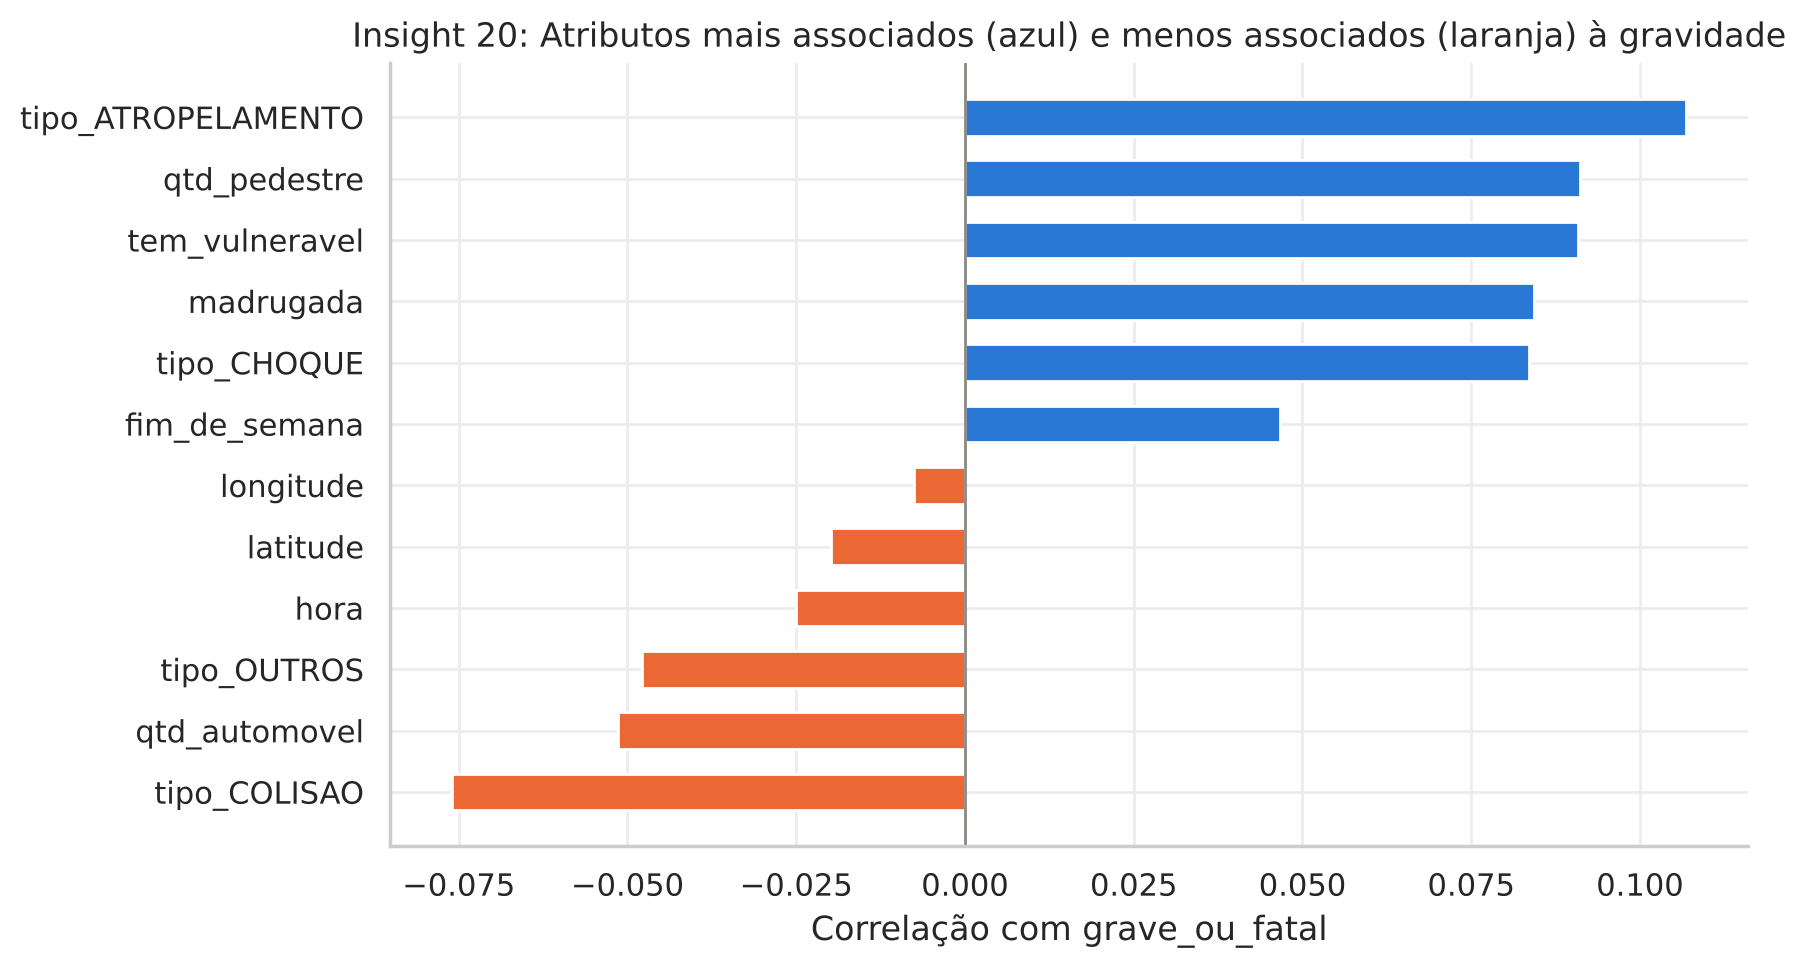

--- Insight 20: Correlações lineares mais fortes ---
Maior positiva: tipo_ATROPELAMENTO (+0.107) | Maior negativa: tipo_COLISAO (-0.076)


In [21]:
correlacoes = X_total.corrwith(y_total).dropna().sort_values()
extremos = pd.concat([correlacoes.head(6), correlacoes.tail(6)])

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(extremos.index, extremos.values, color=[LARANJA if v < 0 else AZUL for v in extremos.values], height=0.6)
ax.axvline(0, color=CINZA, lw=1)
ax.set_xlabel("Correlação com grave_ou_fatal")
ax.spines[["top", "right"]].set_visible(False)
plt.title("Insight 20: Atributos mais associados (azul) e menos associados (laranja) à gravidade")
plt.tight_layout()
plt.show()

print("--- Insight 20: Correlações lineares mais fortes ---")
print(f"Maior positiva: {correlacoes.idxmax()} ({correlacoes.max():+.3f}) | "
      f"Maior negativa: {correlacoes.idxmin()} ({correlacoes.min():+.3f})")

# **Divisão Temporal em Treino e Teste**

In [22]:
ultimo_ano = int(base_modelo["ano"].max())
mascara_teste = (base_modelo["ano"] == ultimo_ano).values

X_train, X_test = X_total[~mascara_teste], X_total[mascara_teste]
y_train, y_test = y_total[~mascara_teste], y_total[mascara_teste]

print("--- Insight 21: Divisão treino/teste ---")
print(f"Treino: 2022 a {ultimo_ano - 1} -> {len(X_train):,} sinistros ({len(X_train) / len(X_total):.0%}) | "
      f"taxa grave {y_train.mean():.2%}")
print(f"Teste: {ultimo_ano} (dados nunca vistos) -> {len(X_test):,} sinistros ({len(X_test) / len(X_total):.0%}) | "
      f"taxa grave {y_test.mean():.2%}")
print("A divisão por tempo simula o uso real: o modelo aprende com o passado e é avaliado no ano seguinte.")

--- Insight 21: Divisão treino/teste ---
Treino: 2022 a 2025 -> 109,961 sinistros (87%) | taxa grave 9.96%
Teste: 2026 (dados nunca vistos) -> 16,995 sinistros (13%) | taxa grave 11.97%
A divisão por tempo simula o uso real: o modelo aprende com o passado e é avaliado no ano seguinte.


# **Escolha e Justificativa do Modelo (XGBoost)**

In [23]:
peso_positivo = (y_train == 0).sum() / (y_train == 1).sum()

print("--- Insight 22: Por que XGBoost ---")
print("1. Os dados são tabulares e misturam atributos numéricos e binários; árvores com boosting são o estado da arte nesse cenário.")
print("2. A gravidade depende de combinações (ex.: moto + madrugada + rodovia); o XGBoost captura essas interações sem precisar criá-las à mão.")
print("3. Não exige normalização e lida bem com contagens, coordenadas e indicadores binários no mesmo modelo.")
print(f"4. O desbalanceamento é corrigido pelo parâmetro scale_pos_weight = {peso_positivo:.2f} (casos leves / casos graves).")
print("5. Tem regularização e controle de profundidade, o que permite medir e controlar overfitting nos hiperparâmetros.")
print("6. É rápido o suficiente para rodar validação cruzada em 12 combinações com ~100 mil linhas no Colab.")

--- Insight 22: Por que XGBoost ---
1. Os dados são tabulares e misturam atributos numéricos e binários; árvores com boosting são o estado da arte nesse cenário.
2. A gravidade depende de combinações (ex.: moto + madrugada + rodovia); o XGBoost captura essas interações sem precisar criá-las à mão.
3. Não exige normalização e lida bem com contagens, coordenadas e indicadores binários no mesmo modelo.
4. O desbalanceamento é corrigido pelo parâmetro scale_pos_weight = 9.04 (casos leves / casos graves).
5. Tem regularização e controle de profundidade, o que permite medir e controlar overfitting nos hiperparâmetros.
6. É rápido o suficiente para rodar validação cruzada em 12 combinações com ~100 mil linhas no Colab.


# **Grade de Hiperparâmetros (12 Combinações de 3 Hiperparâmetros)**

In [24]:
grade = {
    "max_depth": [3, 5, 7],
    "learning_rate": [0.05, 0.1],
    "n_estimators": [200, 500],
}

modelo_base = XGBClassifier(objective="binary:logistic", tree_method="hist", subsample=0.8,
                            colsample_bytree=0.8, scale_pos_weight=peso_positivo,
                            eval_metric="logloss", random_state=SEED, n_jobs=-1)

n_combinacoes = int(np.prod([len(v) for v in grade.values()]))
print("--- Insight 23: Espaço de busca ---")
for k, v in grade.items():
    print(f"{k}: {v}")
print(f"Total: {n_combinacoes} combinações x 5 folds = {n_combinacoes * 5} treinos, todos só na base de treino.")

--- Insight 23: Espaço de busca ---
max_depth: [3, 5, 7]
learning_rate: [0.05, 0.1]
n_estimators: [200, 500]
Total: 12 combinações x 5 folds = 60 treinos, todos só na base de treino.


# **Treinamento com Validação Cruzada (Somente no Treino)**

In [25]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
busca = GridSearchCV(modelo_base, grade, cv=cv, n_jobs=1, return_train_score=True, refit="roc_auc",
                     scoring={"roc_auc": "roc_auc", "average_precision": "average_precision",
                              "recall": "recall", "f1": "f1"})
busca.fit(X_train, y_train)

resultados = pd.DataFrame(busca.cv_results_)
tabela_cv = pd.DataFrame({
    "max_depth": resultados["param_max_depth"],
    "learning_rate": resultados["param_learning_rate"],
    "n_estimators": resultados["param_n_estimators"],
    "AUC_treino": resultados["mean_train_roc_auc"],
    "AUC_validacao": resultados["mean_test_roc_auc"],
    "desvio_validacao": resultados["std_test_roc_auc"],
    "AP_validacao": resultados["mean_test_average_precision"],
    "recall_validacao": resultados["mean_test_recall"],
})
tabela_cv["gap_AUC"] = tabela_cv["AUC_treino"] - tabela_cv["AUC_validacao"]
tabela_cv = tabela_cv.sort_values("AUC_validacao", ascending=False).reset_index(drop=True).round(4)

print("--- Insight 24: Resultado das 12 combinações na validação cruzada ---")
display(tabela_cv)

--- Insight 24: Resultado das 12 combinações na validação cruzada ---


,max_depth,learning_rate,n_estimators,AUC_treino,AUC_validacao,desvio_validacao,AP_validacao,recall_validacao,gap_AUC
0,5,0.05,200,0.7555,0.7167,0.0026,0.2705,0.6033,0.0388
1,3,0.05,500,0.7379,0.7165,0.0038,0.2674,0.6157,0.0214
2,3,0.10,200,0.7332,0.7152,0.0035,0.2653,0.6156,0.0180
3,3,0.10,500,0.7538,0.7146,0.0040,0.2664,0.6061,0.0392
4,5,0.10,200,0.7846,0.7136,0.0030,0.2668,0.5829,0.0711
5,3,0.05,200,0.7231,0.7126,0.0035,0.2607,0.6150,0.0104
6,5,0.05,500,0.7987,0.7126,0.0031,0.2668,0.5745,0.0861
7,7,0.05,200,0.8177,0.7112,0.0017,0.2659,0.5566,0.1065
8,5,0.10,500,0.8443,0.7011,0.0031,0.2575,0.5270,0.1432
9,7,0.10,200,0.8752,0.6988,0.0028,0.2546,0.4990,0.1764


# **Treino x Validação por Combinação (Curva de Overfitting)**

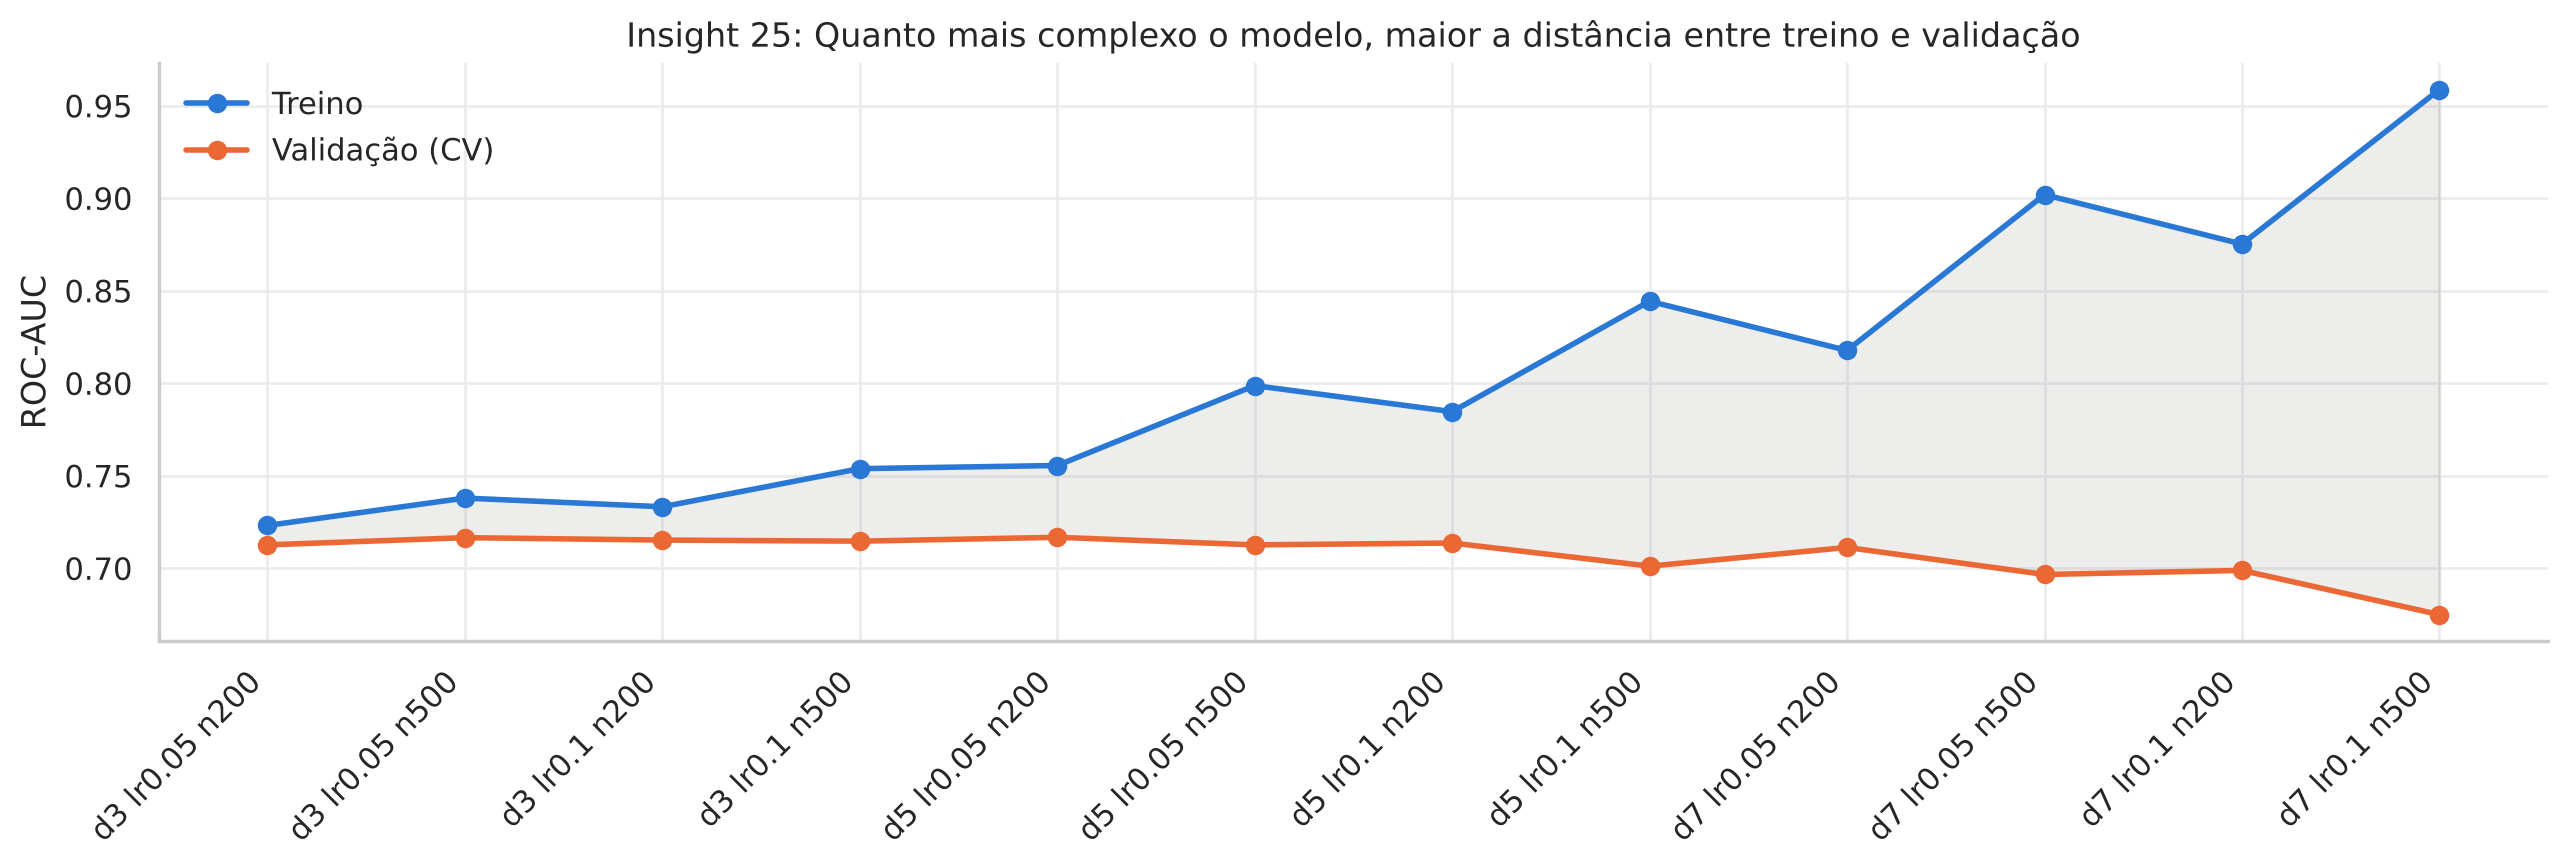

--- Insight 25: Overfitting por complexidade ---
Menor gap: 0.0104 (d3 lr0.05 n200) | Maior gap: 0.2838 (d7 lr0.1 n500)


In [26]:
ordem = tabela_cv.sort_values(["max_depth", "learning_rate", "n_estimators"]).reset_index(drop=True)
rotulos = [f"d{r.max_depth} lr{r.learning_rate} n{r.n_estimators}" for r in ordem.itertuples()]

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(rotulos, ordem["AUC_treino"], marker="o", lw=2, color=AZUL, label="Treino")
ax.plot(rotulos, ordem["AUC_validacao"], marker="o", lw=2, color=LARANJA, label="Validação (CV)")
ax.fill_between(range(len(ordem)), ordem["AUC_validacao"], ordem["AUC_treino"], color=CINZA, alpha=0.15)
ax.set_ylabel("ROC-AUC")
ax.legend(frameon=False)
plt.xticks(rotation=45, ha="right")
ax.spines[["top", "right"]].set_visible(False)
plt.title("Insight 25: Quanto mais complexo o modelo, maior a distância entre treino e validação")
plt.tight_layout()
plt.show()

print("--- Insight 25: Overfitting por complexidade ---")
print(f"Menor gap: {ordem.loc[ordem.gap_AUC.idxmin(), 'gap_AUC']:.4f} ({rotulos[ordem.gap_AUC.idxmin()]}) | "
      f"Maior gap: {ordem.loc[ordem.gap_AUC.idxmax(), 'gap_AUC']:.4f} ({rotulos[ordem.gap_AUC.idxmax()]})")

# **Melhor Combinação de Hiperparâmetros**

In [27]:
modelo = busca.best_estimator_
melhor = tabela_cv.iloc[0]

print("--- Insight 26: Configuração vencedora ---")
print("Melhores hiperparâmetros:", busca.best_params_)
print(f"AUC na validação cruzada: {melhor.AUC_validacao:.4f} ± {melhor.desvio_validacao:.4f}")
print(f"Diferença para a pior combinação: {melhor.AUC_validacao - tabela_cv.AUC_validacao.min():+.4f} de AUC")

--- Insight 26: Configuração vencedora ---
Melhores hiperparâmetros: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 200}
AUC na validação cruzada: 0.7167 ± 0.0026
Diferença para a pior combinação: +0.0418 de AUC


# **Métricas em Treino e Teste Lado a Lado**

In [28]:
def avaliar(modelo, X, y, limiar=0.5):
    proba = modelo.predict_proba(X)[:, 1]
    pred = (proba >= limiar).astype(int)
    return {"ROC-AUC": roc_auc_score(y, proba),
            "PR-AUC (Average Precision)": average_precision_score(y, proba),
            "Recall (graves detectados)": recall_score(y, pred),
            "Precisão": precision_score(y, pred),
            "F1": f1_score(y, pred),
            "Acurácia balanceada": balanced_accuracy_score(y, pred),
            "Acurácia": accuracy_score(y, pred)}

proba_train = modelo.predict_proba(X_train)[:, 1]
proba_test = modelo.predict_proba(X_test)[:, 1]

metricas = pd.DataFrame({"Treino": avaliar(modelo, X_train, y_train), "Teste": avaliar(modelo, X_test, y_test)})
metricas["Diferença"] = metricas["Treino"] - metricas["Teste"]

print("--- Insight 27: Desempenho em treino x teste ---")
display(metricas.round(4))
print(f"Referência ingênua: chutar sempre 'leve' daria {1 - y_test.mean():.1%} de acurácia, mas 0% de recall nos graves.")
print(f"Referência aleatória da PR-AUC = taxa de graves no teste = {y_test.mean():.3f}.")

--- Insight 27: Desempenho em treino x teste ---


,Treino,Teste,Diferença
ROC-AUC,0.7498,0.7103,0.0396
PR-AUC (Average Precision),0.3138,0.2986,0.0152
Recall (graves detectados),0.6563,0.6393,0.0170
Precisão,0.1956,0.2108,-0.0152
F1,0.3014,0.3170,-0.0157
Acurácia balanceada,0.6788,0.6569,0.0219
Acurácia,0.6968,0.6702,0.0266


Referência ingênua: chutar sempre 'leve' daria 88.0% de acurácia, mas 0% de recall nos graves.
Referência aleatória da PR-AUC = taxa de graves no teste = 0.120.


# **Gráfico Comparativo das Métricas (Treino x Teste)**

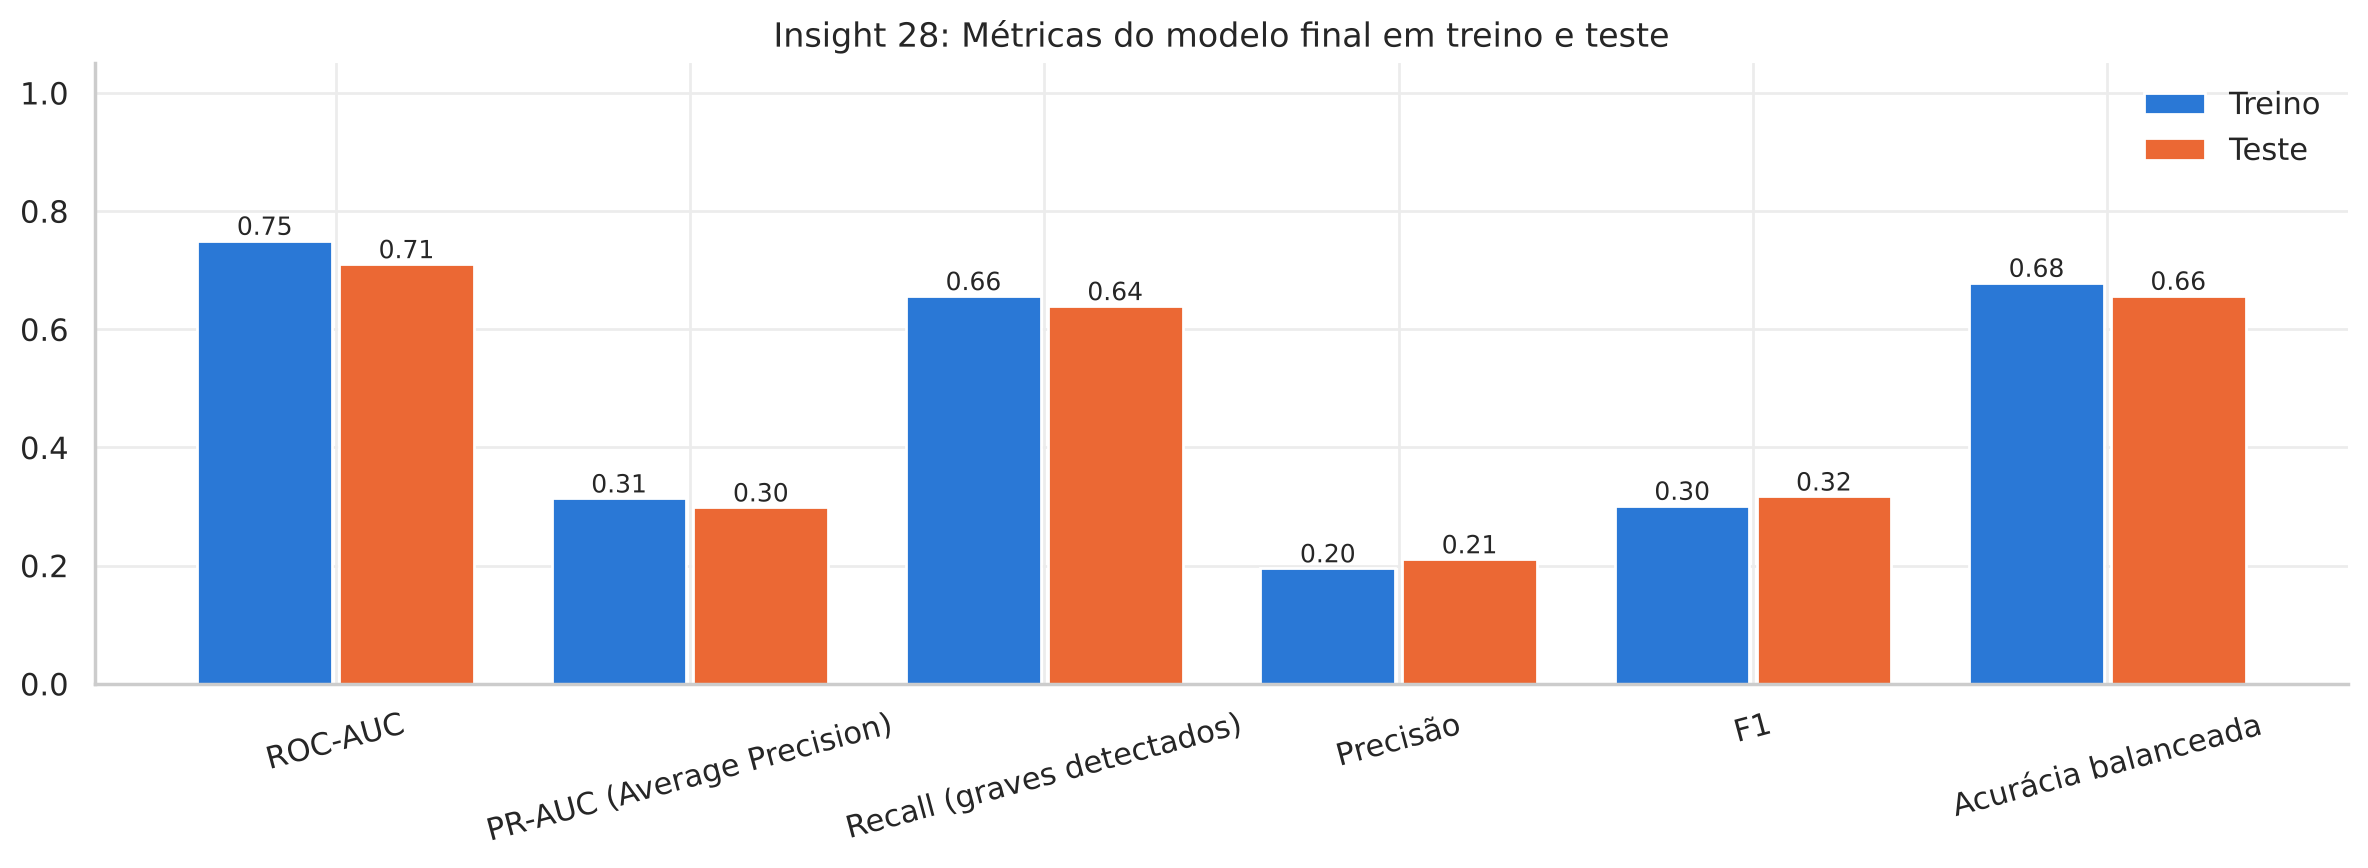

--- Insight 28: Leitura do gráfico ---
Maior queda treino->teste: ROC-AUC (+0.040)


In [29]:
plot_metricas = metricas.drop(index="Acurácia")[["Treino", "Teste"]]
x = np.arange(len(plot_metricas))

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(x - 0.2, plot_metricas["Treino"], 0.38, color=AZUL, label="Treino")
ax.bar(x + 0.2, plot_metricas["Teste"], 0.38, color=LARANJA, label="Teste")
for i, (a, b) in enumerate(zip(plot_metricas["Treino"], plot_metricas["Teste"])):
    ax.text(i - 0.2, a + 0.01, f"{a:.2f}", ha="center", fontsize=9)
    ax.text(i + 0.2, b + 0.01, f"{b:.2f}", ha="center", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(plot_metricas.index, rotation=15)
ax.set_ylim(0, 1.05)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.title("Insight 28: Métricas do modelo final em treino e teste")
plt.tight_layout()
plt.show()

print("--- Insight 28: Leitura do gráfico ---")
print(f"Maior queda treino->teste: {metricas['Diferença'].idxmax()} ({metricas['Diferença'].max():+.3f})")

# **Curvas ROC e Precisão-Recall (Treino x Teste)**

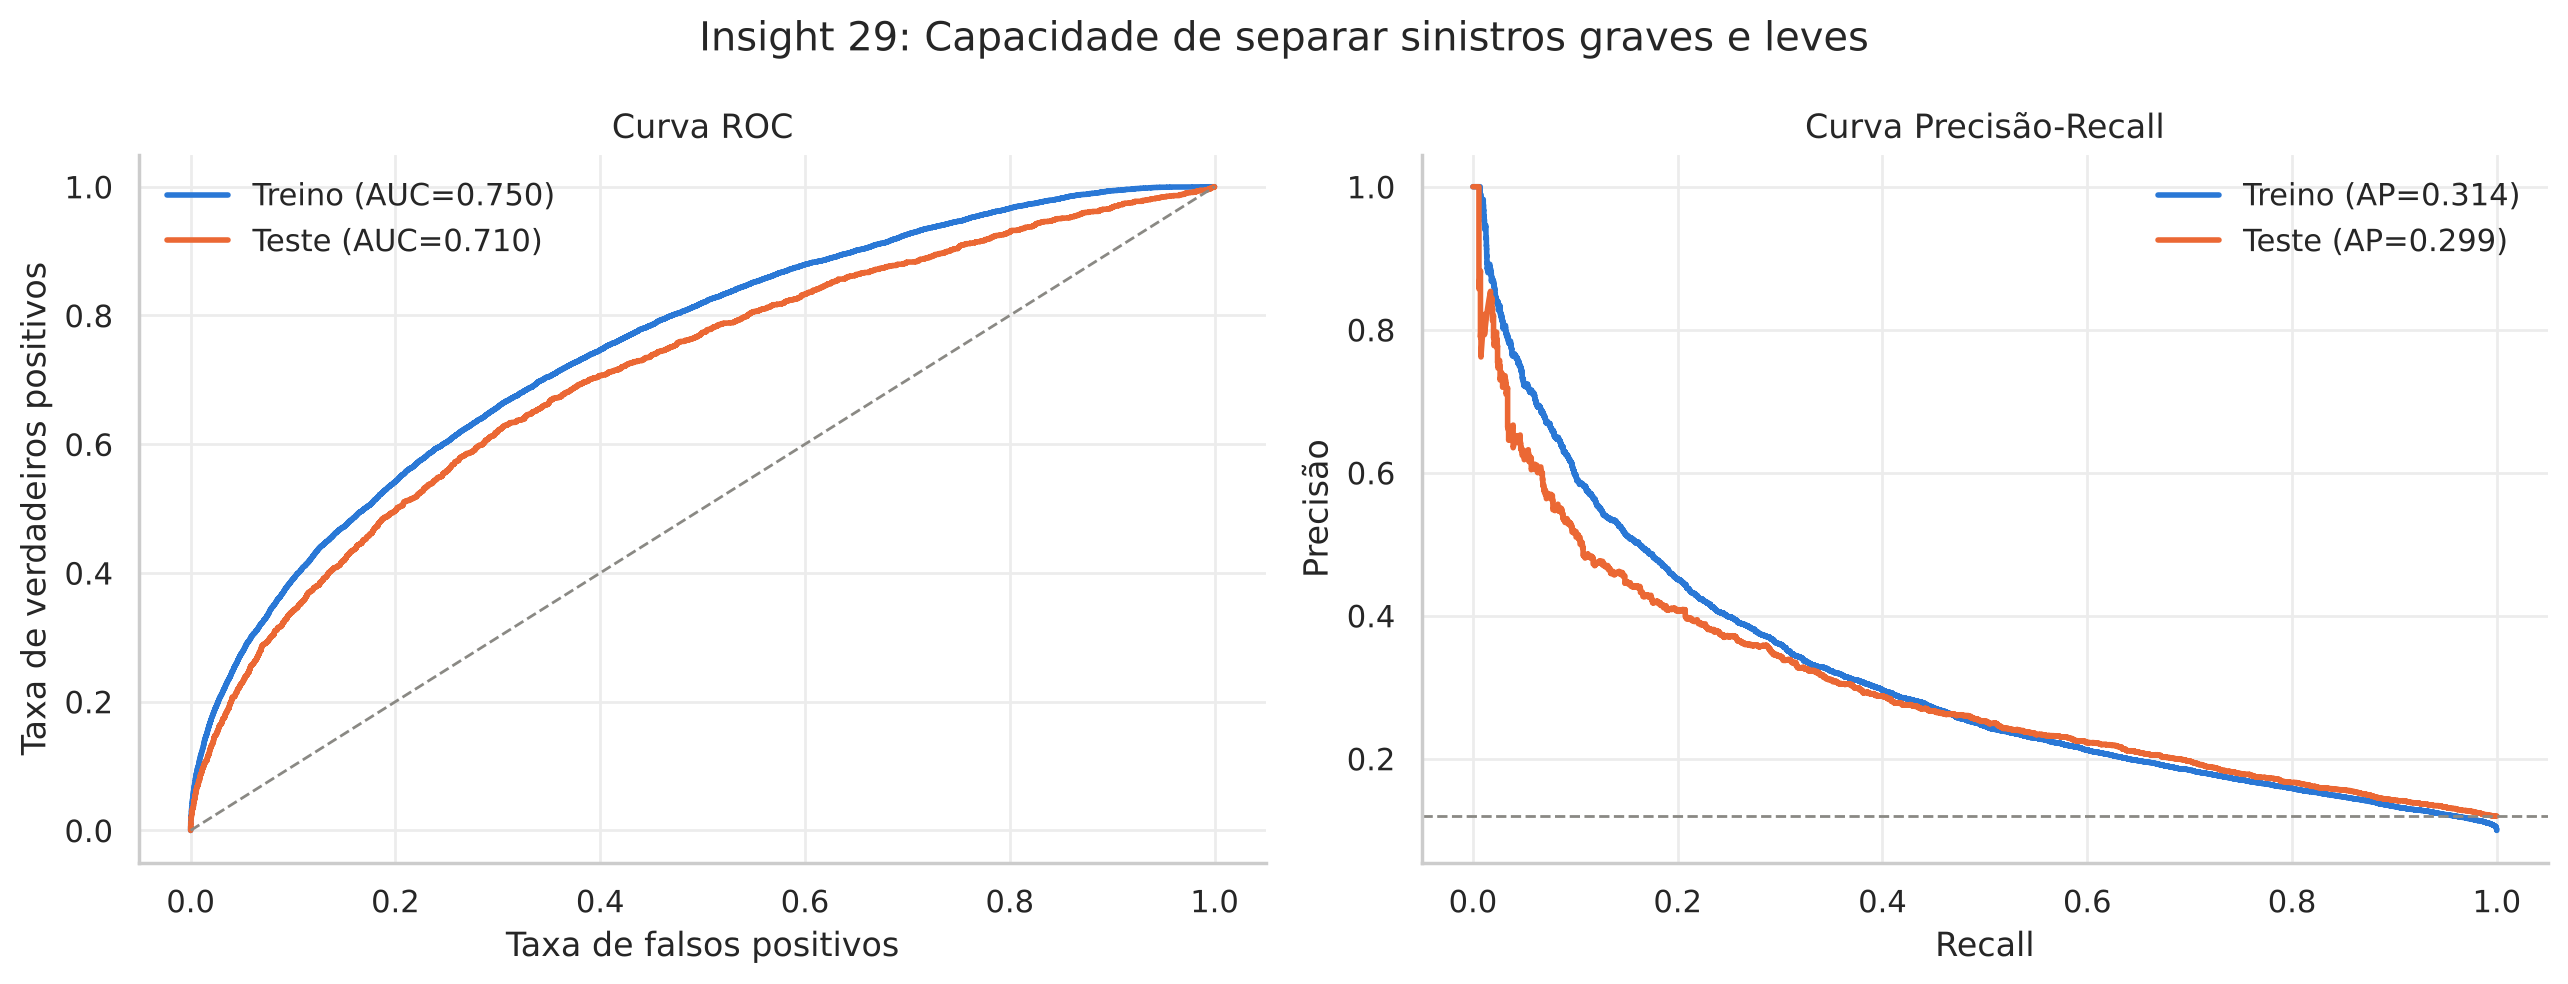

--- Insight 29: Curvas ---
Linhas próximas entre treino e teste indicam que o modelo generaliza para um ano que ele não viu.


In [30]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for nome, y_, p_, cor in [("Treino", y_train, proba_train, AZUL), ("Teste", y_test, proba_test, LARANJA)]:
    fpr, tpr, _ = roc_curve(y_, p_)
    pr, rc, _ = precision_recall_curve(y_, p_)
    ax[0].plot(fpr, tpr, color=cor, lw=2, label=f"{nome} (AUC={roc_auc_score(y_, p_):.3f})")
    ax[1].plot(rc, pr, color=cor, lw=2, label=f"{nome} (AP={average_precision_score(y_, p_):.3f})")
ax[0].plot([0, 1], [0, 1], color=CINZA, ls="--", lw=1)
ax[1].axhline(y_test.mean(), color=CINZA, ls="--", lw=1)
ax[0].set(xlabel="Taxa de falsos positivos", ylabel="Taxa de verdadeiros positivos", title="Curva ROC")
ax[1].set(xlabel="Recall", ylabel="Precisão", title="Curva Precisão-Recall")
for a in ax:
    a.legend(frameon=False)
    a.spines[["top", "right"]].set_visible(False)
plt.suptitle("Insight 29: Capacidade de separar sinistros graves e leves")
plt.tight_layout()
plt.show()

print("--- Insight 29: Curvas ---")
print("Linhas próximas entre treino e teste indicam que o modelo generaliza para um ano que ele não viu.")

# **Matriz de Confusão no Conjunto de Teste**

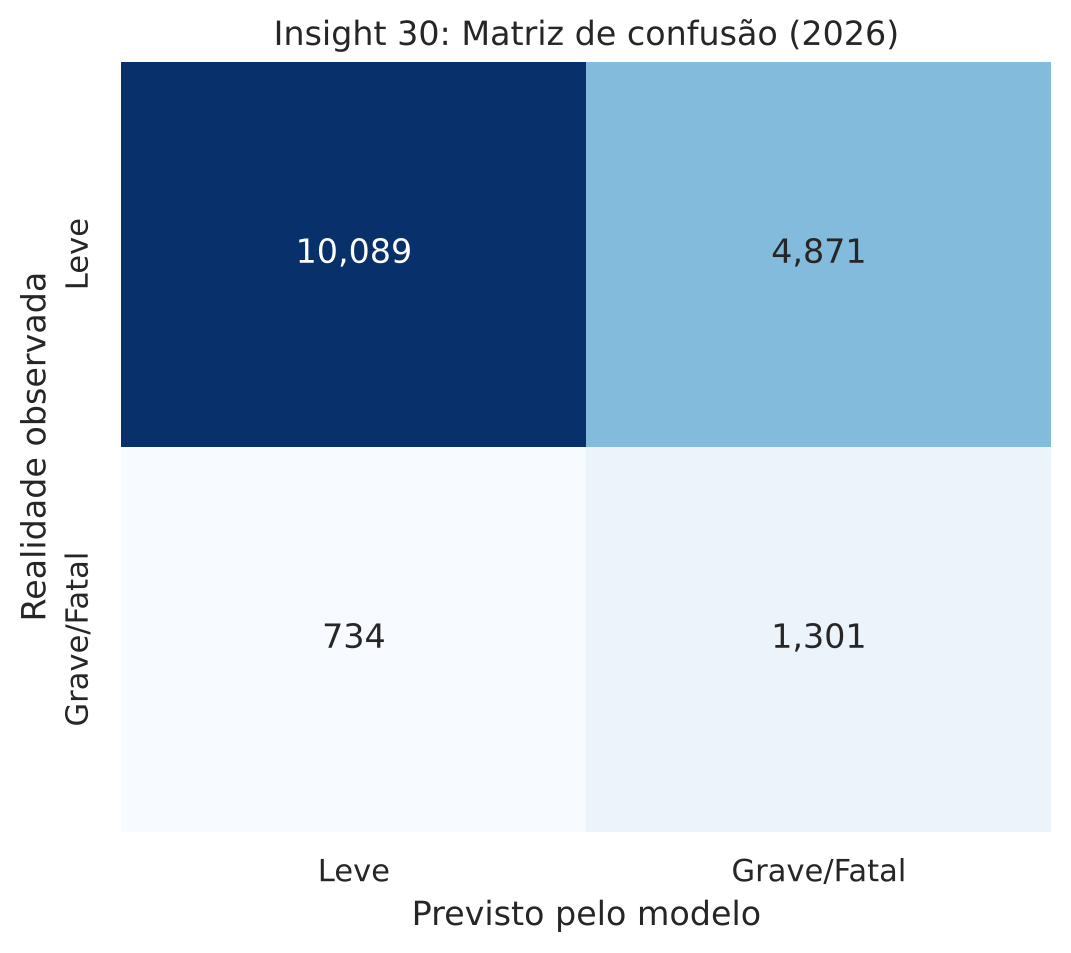

--- Insight 30: Acertos e erros em casos reais ---
Graves identificados corretamente: 1,301 de 2,035 (63.9%)
Graves que passaram despercebidos: 734
Alarmes falsos (leves marcados como graves): 4,871 de 14,960 leves (32.6%)


In [31]:
pred_test = (proba_test >= 0.5).astype(int)
mc = confusion_matrix(y_test, pred_test)

plt.figure(figsize=(6, 5))
sns.heatmap(mc, annot=True, fmt=",d", cmap="Blues", cbar=False,
            xticklabels=["Leve", "Grave/Fatal"], yticklabels=["Leve", "Grave/Fatal"])
plt.xlabel("Previsto pelo modelo")
plt.ylabel("Realidade observada")
plt.title(f"Insight 30: Matriz de confusão ({ultimo_ano})")
plt.show()

tn, fp, fn, tp = mc.ravel()
print("--- Insight 30: Acertos e erros em casos reais ---")
print(f"Graves identificados corretamente: {tp:,} de {tp + fn:,} ({tp / (tp + fn):.1%})")
print(f"Graves que passaram despercebidos: {fn:,}")
print(f"Alarmes falsos (leves marcados como graves): {fp:,} de {tn + fp:,} leves ({fp / (tn + fp):.1%})")

# **Discussão de Overfitting**

In [32]:
gap_auc = metricas.loc["ROC-AUC", "Diferença"]
gap_cv = melhor.gap_AUC

print("--- Insight 31: Diagnóstico de overfitting ---")
print(f"AUC treino: {metricas.loc['ROC-AUC', 'Treino']:.4f} | AUC validação cruzada: {melhor.AUC_validacao:.4f} | "
      f"AUC teste: {metricas.loc['ROC-AUC', 'Teste']:.4f}")
print(f"Gap treino-teste: {gap_auc:.4f} | Gap treino-validação no CV: {gap_cv:.4f}")
if gap_auc < 0.03:
    print("Gap pequeno: o modelo escolhido não decorou o treino e mantém o desempenho em dados novos.")
elif gap_auc < 0.08:
    print("Gap moderado: há algum ajuste ao treino, mas o desempenho em teste segue consistente.")
else:
    print("Gap alto: sinal de overfitting; combinações mais rasas seriam preferíveis.")
print(f"Nas 12 combinações, árvores com max_depth=7 e 500 árvores tiveram gap médio de "
      f"{tabela_cv[(tabela_cv.max_depth == 7) & (tabela_cv.n_estimators == 500)].gap_AUC.mean():.4f}, "
      f"contra {tabela_cv[(tabela_cv.max_depth == 3)].gap_AUC.mean():.4f} das árvores com max_depth=3.")
print("A validação cruzada foi feita só no treino e o teste é um ano inteiro posterior, então não há vazamento temporal.")

--- Insight 31: Diagnóstico de overfitting ---
AUC treino: 0.7498 | AUC validação cruzada: 0.7167 | AUC teste: 0.7103
Gap treino-teste: 0.0396 | Gap treino-validação no CV: 0.0388
Gap moderado: há algum ajuste ao treino, mas o desempenho em teste segue consistente.
Nas 12 combinações, árvores com max_depth=7 e 500 árvores tiveram gap médio de 0.2446, contra 0.0222 das árvores com max_depth=3.
A validação cruzada foi feita só no treino e o teste é um ano inteiro posterior, então não há vazamento temporal.


# **Importância dos Atributos no Modelo Final**

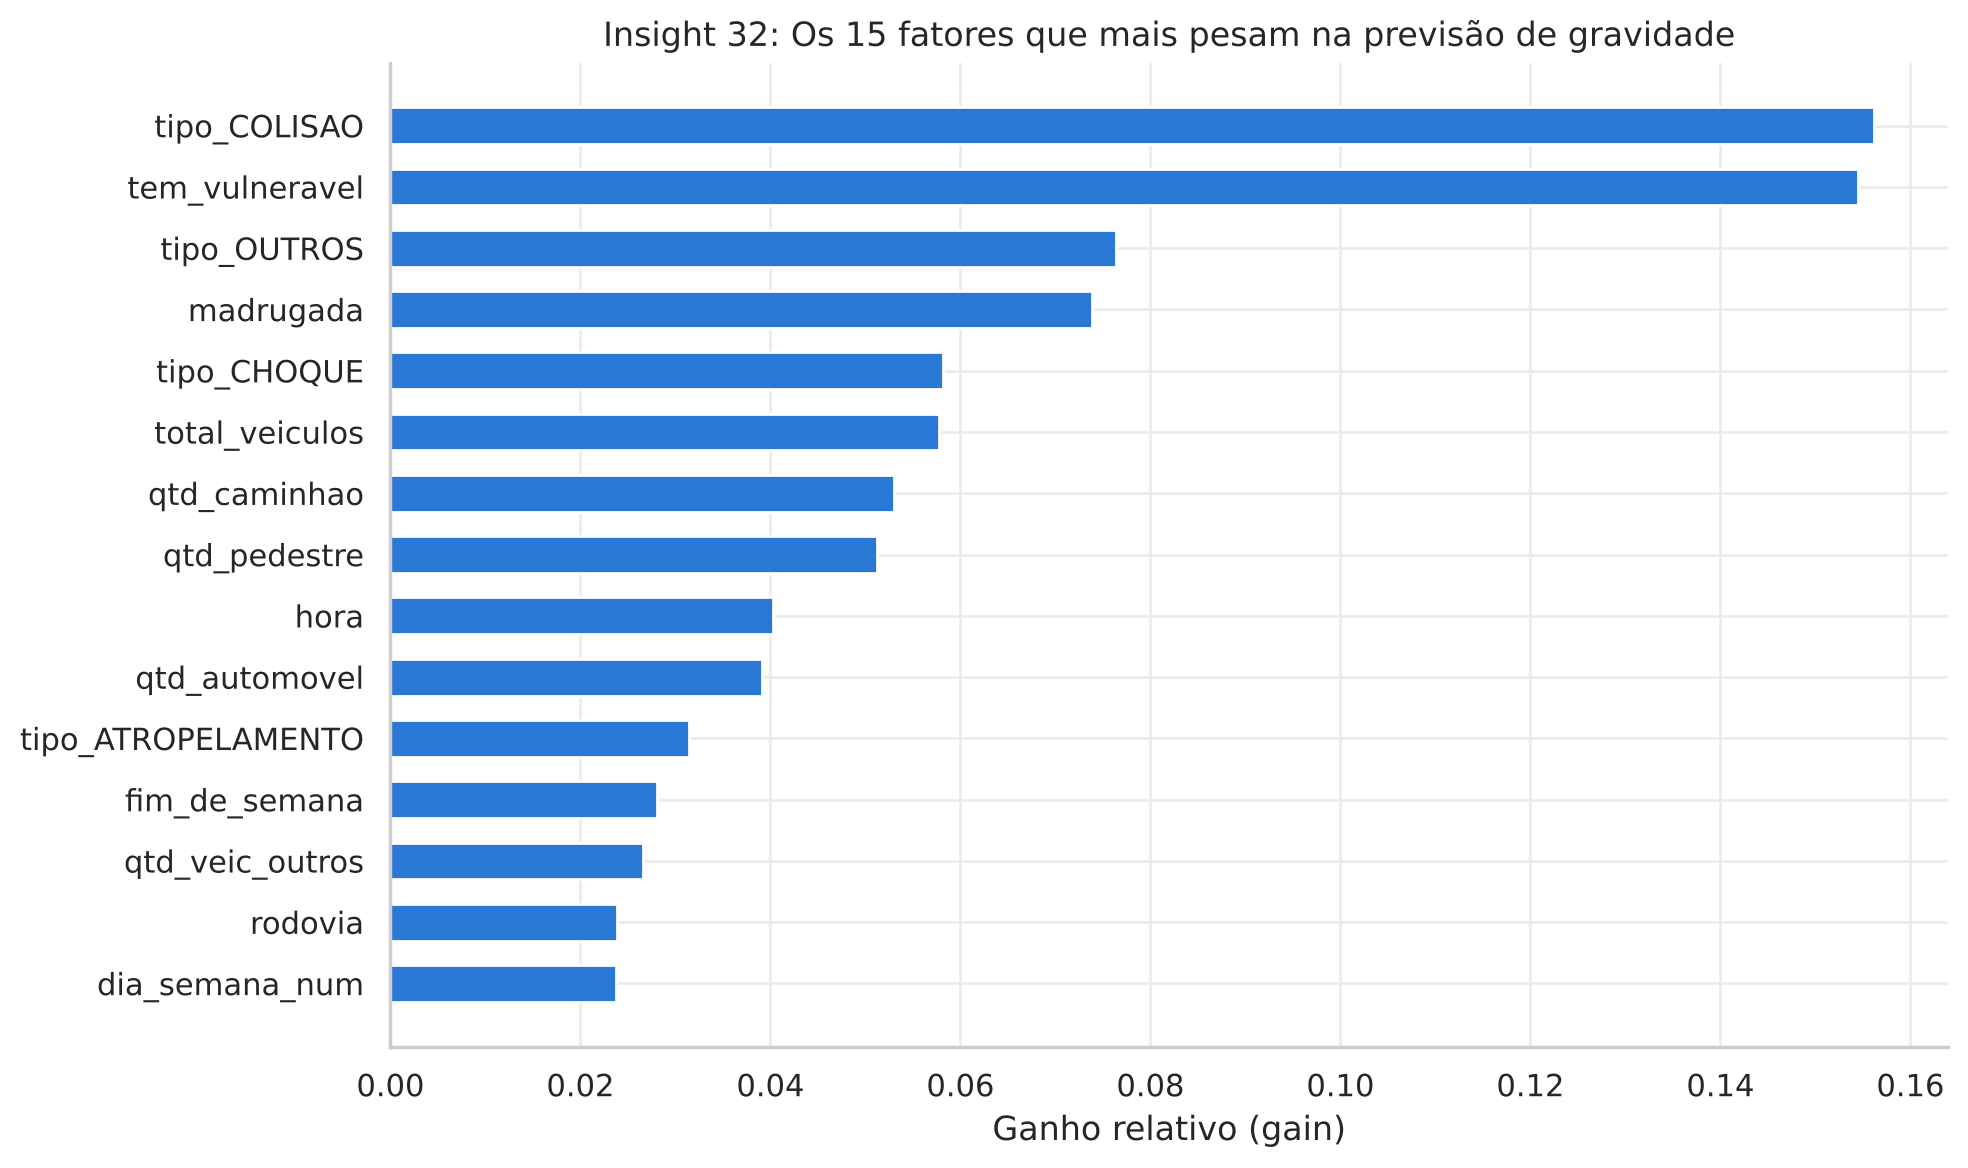

--- Insight 32: Ranking de fatores ---


,importância
tipo_COLISAO,0.1562
tem_vulneravel,0.1545
tipo_OUTROS,0.0763
madrugada,0.0738
tipo_CHOQUE,0.0582
total_veiculos,0.0577
qtd_caminhao,0.0530
qtd_pedestre,0.0512
hora,0.0403
qtd_automovel,0.0391


In [33]:
importancia = (pd.Series(modelo.get_booster().get_score(importance_type="gain"))
                 .reindex(X_train.columns).fillna(0))
importancia = (importancia / importancia.sum()).sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(importancia.index[::-1], importancia.values[::-1], color=AZUL, height=0.6)
ax.set_xlabel("Ganho relativo (gain)")
ax.spines[["top", "right"]].set_visible(False)
plt.title("Insight 32: Os 15 fatores que mais pesam na previsão de gravidade")
plt.tight_layout()
plt.show()

print("--- Insight 32: Ranking de fatores ---")
display(importancia.round(4).to_frame("importância"))

# **Escolha do Limiar para Uso Operacional**

In [34]:
limiares = [0.3, 0.4, 0.5, 0.6, 0.7]
tabela_limiar = pd.DataFrame([{"limiar": l,
                               "recall_graves": recall_score(y_test, proba_test >= l),
                               "precisao": precision_score(y_test, proba_test >= l),
                               "% sinistros sinalizados": (proba_test >= l).mean()} for l in limiares]).round(3)

print("--- Insight 33: Troca entre detectar graves e gerar alertas ---")
display(tabela_limiar)
print("Limiar menor = mais graves detectados e mais alertas; limiar maior = menos alertas e mais graves perdidos.")

--- Insight 33: Troca entre detectar graves e gerar alertas ---


,limiar,recall_graves,precisao,% sinistros sinalizados
0,0.3,0.962,0.129,0.893
1,0.4,0.813,0.164,0.594
2,0.5,0.639,0.211,0.363
3,0.6,0.438,0.270,0.194
4,0.7,0.241,0.376,0.077


Limiar menor = mais graves detectados e mais alertas; limiar maior = menos alertas e mais graves perdidos.


# **Conclusão e Leitura para o Cidadão**

In [35]:
taxa_alto_risco = y_test[proba_test >= 0.5].mean()
taxa_baixo_risco = y_test[proba_test < 0.5].mean()

print("--- Insight 34: O que o resultado significa para quem vive em São Paulo ---")
print(f"1. Com dados reais do INFOSIGA, o modelo separa sinistros graves e leves com ROC-AUC de "
      f"{metricas.loc['ROC-AUC', 'Teste']:.2f} em {ultimo_ano}, um ano que ele nunca viu.")
print(f"2. Entre os sinistros marcados como alto risco, {taxa_alto_risco:.1%} foram de fato graves ou fatais; "
      f"entre os de baixo risco, só {taxa_baixo_risco:.1%}. Isso é {taxa_alto_risco / taxa_baixo_risco:.1f}x mais concentração.")
print(f"3. O modelo encontrou {recall_score(y_test, pred_test):.0%} dos sinistros graves logo no registro, "
      f"o que ajuda a priorizar SAMU e resgate onde a chance de morte é maior.")
print(f"4. Atropelamentos ({atrop:.1%} graves), a madrugada (pico às {int(pico)}h, {por_hora['mean'].max():.1%}), "
      f"fins de semana ({fds[1]:.1%}) e rodovias ({por_via.loc['ESTRADAS E RODOVIAS', 'taxa_grave']:.1f}%) são os cenários mais letais.")
print(f"   As motos não são as mais letais por caso, mas estão em {vulneraveis.loc['Moto envolvida', 'participação_%']:.0f}% "
      f"dos sinistros com vítima, por isso somam muitas vítimas graves em números absolutos.")
print(f"5. As 10 vias com mais casos graves concentram {top_vias.graves_ou_fatais.sum() / df.grave_ou_fatal.sum():.1%} "
      f"dos casos da cidade: são candidatas naturais a fiscalização, redução de velocidade e travessias seguras.")
print(f"6. Limitação: o modelo indica risco, não causa. Faltam dados como velocidade, clima e uso de capacete, "
      f"que podem ser integrados (ex.: INMET) em versões futuras.")

--- Insight 34: O que o resultado significa para quem vive em São Paulo ---
1. Com dados reais do INFOSIGA, o modelo separa sinistros graves e leves com ROC-AUC de 0.71 em 2026, um ano que ele nunca viu.
2. Entre os sinistros marcados como alto risco, 21.1% foram de fato graves ou fatais; entre os de baixo risco, só 6.8%. Isso é 3.1x mais concentração.
3. O modelo encontrou 64% dos sinistros graves logo no registro, o que ajuda a priorizar SAMU e resgate onde a chance de morte é maior.
4. Atropelamentos (18.7% graves), a madrugada (pico às 2h, 20.5%), fins de semana (12.7%) e rodovias (13.0%) são os cenários mais letais.
   As motos não são as mais letais por caso, mas estão em 64% dos sinistros com vítima, por isso somam muitas vítimas graves em números absolutos.
5. As 10 vias com mais casos graves concentram 11.5% dos casos da cidade: são candidatas naturais a fiscalização, redução de velocidade e travessias seguras.
6. Limitação: o modelo indica risco, não causa. Faltam dados como 